# Calculate single perturbation score per variant

We want one overall edgotyping score to make variant-level hit calls. Here we explore several strategies for this:

- call the variant "perturbed" if any edge is perturbed
- compute the fraction of perturbed edges and find some way to calibrate this score
- calculate the Euclidean distance between profiles and find some way to calibrate this score

# Automated

In [55]:
import pandas as pd
import polars as pl
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.covariance import LedoitWolf

import os

import sys
sys.path.append("../../../1_allele_collection/2_analysis")
from plot_utils import *

sys.path.append("../..")
from analyses_plot_utils import *

In [56]:
outputs_dir = "../3_outputs/sqY2H"
meta_outputs = "../../../1_allele_collection/3_outputs"

In [57]:
from scipy.spatial.distance import mahalanobis
from scipy.linalg import pinv

# Calculate Euclidean distance for each variant relative to it's wildtype reference
orf_profiles = [f for f in os.listdir(f"{outputs_dir}/edgotype_profiles/auto_summed") if "_auto_summed" in f]

zero_col = "0"
perturbed_thresh = 0.5 # edge called "perturbed" if >= 50% decrease compared to wt reference
orf_distances = []

all_perturbations = []
all_log2s = []

wt_thresh = [0, 0.1, 0.2, 0.3, 0.4, 0.5]

# print(orf_profiles)

for orf in orf_profiles:
    profiles = pl.read_csv(f"{outputs_dir}/edgotype_profiles/auto_summed/{orf}")
    
    # filter out edges where the WT could not be measured
    profiles = profiles.filter(~pl.col("0").is_null())

    db_orf_id = orf.replace("orf_id_", "")
    db_orf_id = db_orf_id.replace("_auto_summed.csv", "")

    columns = [col for col in profiles.columns if col != "ad_orf_id"]

    # "impute" missing values as the mean for that variant
    profiles_filled = profiles.with_columns([
        pl.when(pl.col(col).is_null())
        .then(pl.col(col).mean())
        .otherwise(pl.col(col))
        .alias(col)
        for col in columns
    ])
    print('db_orf_id', db_orf_id)
    
    # compute distances
    distance_rows = []
    for col in columns:
        if col == zero_col:
            continue
        
        # Euclidean distance
        diff_squared = (profiles_filled[col] - profiles_filled[zero_col]) ** 2
        distances = np.sqrt(diff_squared.sum())

        # Cosine similarity
        wt = profiles_filled.select(zero_col).to_numpy()
        var = profiles_filled.select(col).to_numpy()

        # Add to your distance calculation loop
        max_perturbation = (profiles_filled[zero_col] - profiles_filled[col]).max()
        max_perturbation_abs = abs(max_perturbation)
        max_perturbation_fold = (profiles_filled[zero_col] / profiles_filled[col]).max()
        # max_perturbation_fold = (profiles_filled[col] / profiles_filled[zero_col]).max()
        max_perturbation_fold_abs = abs(max_perturbation_fold)
        max_relative_perturbation = ((profiles_filled[col] - profiles_filled[zero_col]) / profiles_filled[zero_col]).max()
        # Log2 fold change calculation
        max_log2_fold_change = np.log2(max_perturbation_fold) if max_perturbation_fold > 0 else np.log2(max_perturbation_fold + 0.0001)
        max_log2_fold_change_abs = abs(max_log2_fold_change) if max_log2_fold_change is not None else None

        
        
        
        # Node removal detection metrics
        # perturbations = profiles_filled[zero_col] - profiles_filled[col] 
        perturbations = profiles_filled[col] -  profiles_filled[zero_col] 
        relative_perturbations = perturbations / profiles_filled[zero_col]
        all_perturbations.append(relative_perturbations.to_list())
        # print('var', profiles_filled[col])
        # print('wt', profiles_filled[zero_col])
        # print('perturb',relative_perturbations)
        
        log2fc = np.log2((profiles_filled[col] / profiles_filled[zero_col]) + 0.0001)
        all_log2s.append(log2fc.to_list())
        

        
        mean_wt = profiles_filled[zero_col].mean()
        
        # if (relative_perturbations >5).any():
        #     print(db_orf_id, col)
        #     for a in relative_perturbations.to_list():
        #         print(a)
        #     print('WARNING: relative perturbations > 5, check data')

        # Check if all edges are severely perturbed
        severe_perturbation_threshold = 0.50  # 50% decrease
        low_threshold = 0.25 # 10% decrease
        all_edges_perturbed = (relative_perturbations <= -severe_perturbation_threshold).all()
        # print('all_edges_perturbed', all_edges_perturbed)
        fraction_severely_perturbed = (relative_perturbations <= -severe_perturbation_threshold).mean()
        # print('_________________________________')
        
        no_edges_perturbed = (relative_perturbations > -low_threshold).all()
        
        perturb_list = []
        
        for perturb in relative_perturbations.to_list():
            if perturb <= -severe_perturbation_threshold:
                perturb_list.append('perturbed')
            elif perturb > -low_threshold:
                perturb_list.append('not_perturbed')
            else:
                perturb_list.append('inconclusive')
                
        # print('perturb_list', perturb_list)
        
        
        inconclusive = (
            (relative_perturbations <= -low_threshold) & 
            (relative_perturbations > -severe_perturbation_threshold)
        ).all()
        
        log2fc_tresh = -1
        
        
        log2fc_all_perturbed = (log2fc <= log2fc_tresh).all()
        log2fc_no_perturbed = (log2fc > log2fc_tresh).all()  # corresponds to <20% decrease
        # log2fc fraction of edges perturbed
        fraction_log2fc_perturbed = (log2fc <= log2fc_tresh).mean()

        # if col == '4008':
        #     print('db_orf_id', db_orf_id, 'db_mut_id', col)
        #     print('no_edges_perturbed', no_edges_perturbed)
        #     print('inconclusive', inconclusive)
        #     print('all_edges_perturbed', all_edges_perturbed)
        #     print('fraction_severely_perturbed', fraction_severely_perturbed)
        #     print('log2fc_all_perturbed', log2fc_all_perturbed)
        #     print('log2fc_no_perturbed', log2fc_no_perturbed)
        #     print('fraction_log2fc_perturbed', fraction_log2fc_perturbed)
        #     print('relative_perturbations', relative_perturbations)
        #     print('log2fc', log2fc)
        #     print('__________________________')

        # Mean perturbation across all edges
        mean_perturbation = perturbations.mean()
        mean_relative_perturbation = relative_perturbations.mean()

        # Standard deviation of perturbations (low = uniform perturbation)
        std_relative_perturbation = relative_perturbations.std()

        # Minimum edge value (close to 0 = complete loss)
        min_edge_value = profiles_filled[col].min()
        min_relative_edge_value = (profiles_filled[col] / profiles_filled[zero_col]).min()


        # if wt.ndim == 1:
        #     wt = wt.reshape(-1, 1)
        # if var.ndim == 1:
        #     var = var.reshape(-1, 1)
        # cos_sim = cosine_similarity(wt.T, var.T)
        # cos_dist = 1 - cos_sim

        # calculate frac perturbed
        wt_pass = []
        per_edges = []
        # for thresh in wt_thresh:
        #     filt_wt = profiles.filter(pl.col("0") > thresh)
        #     wt_pass.append(filt_wt.shape[0])
        #     per_edges.append(filt_wt.filter((pl.col(col)/pl.col("0")) <= perturbed_thresh).shape[0])   
            
        # Mahalanobis distance
        try:
            # Calculate covariance matrix from all profiles
            profile_matrix = profiles_filled.select([col2 for col2 in columns]).to_numpy().T
            cov_matrix = np.cov(profile_matrix)
            
            # Use pseudo-inverse for numerical stability
            inv_cov_matrix = pinv(cov_matrix)
            
            wt_profile = profiles_filled.select(zero_col).to_numpy().flatten()
            var_profile = profiles_filled.select(col).to_numpy().flatten()
            
            mahal_distance = mahalanobis(var_profile, wt_profile, inv_cov_matrix)
            print('mahal_distance', mahal_distance, "for", db_orf_id, col)
        
        except:
            # Fallback if covariance matrix is singular
            mahal_distance = None
            print(profile_matrix)
            print(cov_matrix)
            

        # In your Mahalanobis calculation:
        try:
            profile_matrix = profiles_filled.select([col2 for col2 in columns]).to_numpy().T
            
            # Use regularized covariance instead
            lw = LedoitWolf()
            reg_cov = lw.fit(profile_matrix).covariance_
            
            wt_profile = profiles_filled.select(zero_col).to_numpy().flatten()
            var_profile = profiles_filled.select(col).to_numpy().flatten()
            
            mahal_distance_reg = mahalanobis(var_profile, wt_profile, pinv(reg_cov))
        except Exception as e:
            mahal_distance_reg = None
            print(f"Mahalanobis failed for {db_orf_id}: {e}")
            

        distance_rows.append({
            "db_orf_id": db_orf_id,
            "db_mut_id": int(col),
            "euclid_distance": distances,
            "max_perturbation": max_perturbation,
            "max_relative_perturbation": max_relative_perturbation,
            "max_perturbation_abs": max_perturbation_abs,
            "max_perturbation_fold": max_perturbation_fold,
            "max_perturbation_fold_abs": max_perturbation_fold_abs,
            "max_log2_fold_change": max_log2_fold_change,
            "max_log2_fold_change_abs": max_log2_fold_change_abs,
            "mahalanobis_distance": mahal_distance,
            "mahalanobis_distance_reg": mahal_distance_reg,
            # "cosine_distance": cos_dist,
            "num_edges": profiles.shape[0],
            "all_edges_severely_perturbed": all_edges_perturbed,
            "fraction_severely_perturbed": fraction_severely_perturbed,
            "mean_perturbation": mean_perturbation,
            "mean_relative_perturbation": mean_relative_perturbation,
            "std_relative_perturbation": std_relative_perturbation,
            "min_edge_value": min_edge_value,
            "min_relative_edge_value": min_relative_edge_value,
            'no_edges_perturbed': no_edges_perturbed,
            'inconclusive': inconclusive,
            "mean_wt": mean_wt,
            "log2fc_perturbed": log2fc_all_perturbed,
            "log2fc_no_perturbed": log2fc_no_perturbed,
            "fraction_log2fc_perturbed": fraction_log2fc_perturbed,
            # "num_zero_wt": profiles.filter(pl.col("0") == 0).shape[0],
            # "num_per_0.0": per_edges[0],
            # "num_per_0.1": per_edges[1],
            # "num_per_0.2": per_edges[2],
            # "num_per_0.3": per_edges[3],
            # "num_per_0.4": per_edges[4],
            # "num_per_0.5": per_edges[5],
            # "num_edge_0.0": wt_pass[0],
            # "num_edge_0.1": wt_pass[1],
            # "num_edge_0.2": wt_pass[2],
            # "num_edge_0.3": wt_pass[3],
            # "num_edge_0.4": wt_pass[4],
            # "num_edge_0.5": wt_pass[5],
            # "frac_per_0.0": per_edges[0]/wt_pass[0] if wt_pass[0] != 0 else None,
            # "frac_per_0.1": per_edges[1]/wt_pass[1] if wt_pass[1] != 0 else None,
            # "frac_per_0.2": per_edges[2]/wt_pass[2] if wt_pass[2] != 0 else None,
            # "frac_per_0.3": per_edges[3]/wt_pass[3] if wt_pass[3] != 0 else None,
            # "frac_per_0.4": per_edges[4]/wt_pass[4] if wt_pass[4] != 0 else None,
            # "frac_per_0.5": per_edges[5]/wt_pass[5] if wt_pass[5] != 0 else None
        })


    result_profiles = pl.DataFrame(distance_rows)
    orf_distances.append(result_profiles)

# concatentate and normalize wrt dimensionality
orf_distances = pl.concat(orf_distances, how="vertical_relaxed")
orf_distances = orf_distances.with_columns(
    (pl.col("euclid_distance") / pl.col("num_edges").cast(pl.Float64).sqrt()).alias("normalized_euclid_distance"),
    (pl.col("mahalanobis_distance_reg") / pl.col("num_edges").cast(pl.Float64).sqrt()).alias("normalized_mahal_distance_reg"),
    pl.col("db_mut_id").cast(pl.String).alias("db_mut_id"),
    pl.col("db_orf_id").cast(pl.String).alias("db_orf_id"),
)


db_orf_id 9866
[[0.29242136 0.23377081]
 [0.15501373 0.04517527]
 [0.06233704 0.06233704]]
[[0.00171994 0.00322104 0.        ]
 [0.00322104 0.00603224 0.        ]
 [0.         0.         0.        ]]
[[0.29242136 0.23377081]
 [0.15501373 0.04517527]
 [0.06233704 0.06233704]]
[[0.00171994 0.00322104 0.        ]
 [0.00322104 0.00603224 0.        ]
 [0.         0.         0.        ]]
db_orf_id 5442
[[0.69728213 0.67355786 0.18188965 0.48104631]
 [0.60010754 0.57655634 0.46859435 0.75517192]]
[[0.05677027 0.01160306]
 [0.01160306 0.01396511]]
db_orf_id 513
mahal_distance 6.244786955289458 for 513 213754
mahal_distance 0.7521483057863088 for 513 213753
db_orf_id 71337
[[0.20623781 0.5904936  0.15401384]
 [0.08559859 0.08343933 0.04862081]
 [0.22631144 0.66748314 0.24750665]
 [0.04929477 0.06430245 0.07931013]
 [0.05664826 0.06050131 0.06435436]
 [0.26825905 0.30029576 0.33233247]
 [0.17178628 0.09177386 0.15242157]
 [0.13862713 0.10344161 0.0682561 ]
 [0.05719216 0.07005768 0.0829232 ]
 [0

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_37917/2817815518.py:169: RuntimeWarning: Degrees of freedom <= 0 for slice
  cov_matrix = np.cov(profile_matrix)
/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/numpy/lib/function_base.py:2748: RuntimeWarning: divide by zero encountered in divide
  c *= np.true_divide(1, fact)
/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/numpy/lib/function_base.py:2748: RuntimeWarning: invalid value encountered in multiply
  c *= np.true_divide(1, fact)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_37917/2817815518.py:169: RuntimeWarning: Degrees of freedom <= 0 for slice
  cov_matrix = np.cov(profile_matrix)
/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/numpy/lib/function_base.py:2748: RuntimeWarning: divide by zero encountered in divide
  c *= np.true_divide(1, fact)
/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/numpy/lib/function_base.py:2748: Runtime

[[0.3251987  0.2616597  0.42532518 0.33739452]
 [0.18213809 0.31636853 0.38882507 0.49406629]
 [0.24214369 0.26981428 0.41182866 0.37050775]
 [0.02932582 0.36362441 0.43685361 0.42444871]
 [0.11401554 0.32867067 0.2213431  0.2213431 ]
 [0.37372746 0.23764979 0.43409587 0.47763771]
 [0.45100543 0.31911308 0.44864489 0.5852583 ]
 [0.35556973 0.36726178 0.42209555 0.52405122]
 [0.32977837 0.37653788 0.41833302 0.64127475]
 [0.05846732 0.33732942 0.19789837 0.19789837]
 [0.58010177 0.58010177 0.49489849 0.66530504]
 [0.3151853  0.47389744 0.47389744 0.63260958]
 [0.36033665 0.36033665 0.36033665 0.36033665]
 [0.40268209 0.40268209 0.31043454 0.49492965]
 [0.05387135 0.29457346 0.48366962 0.63195264]
 [0.50187104 0.52799991 0.39061995 0.57642475]
 [0.3933926  0.25241351 0.32290305 0.32290305]
 [0.48523922 0.48523922 0.35225905 0.61821938]
 [0.05409717 0.25596569 0.15503143 0.15503143]]
[[ 0.00453877  0.0026694   0.00427496  0.00350538 -0.00227316  0.00520468
   0.00326043  0.00165472  0.001

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_37917/2817815518.py:169: RuntimeWarning: Degrees of freedom <= 0 for slice
  cov_matrix = np.cov(profile_matrix)
/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/numpy/lib/function_base.py:2748: RuntimeWarning: divide by zero encountered in divide
  c *= np.true_divide(1, fact)
/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/numpy/lib/function_base.py:2748: RuntimeWarning: invalid value encountered in multiply
  c *= np.true_divide(1, fact)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_37917/2817815518.py:169: RuntimeWarning: Degrees of freedom <= 0 for slice
  cov_matrix = np.cov(profile_matrix)
/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/numpy/lib/function_base.py:2748: RuntimeWarning: divide by zero encountered in divide
  c *= np.true_divide(1, fact)
/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/numpy/lib/function_base.py:2748: Runtime

[[0.44345383 0.72402747]
 [0.46473937 0.45135939]
 [0.54985862 0.72633053]
 [0.51817039 0.76683467]
 [0.47533553 0.80567945]
 [0.51389435 0.66242944]
 [0.15596438 0.12121188]
 [0.59331255 0.61245155]
 [0.07393628 0.56323223]
 [0.75172665 0.59536201]
 [0.40180165 0.24136199]
 [0.62325274 0.53949556]
 [0.50691538 0.61742504]
 [0.31093189 0.51607922]
 [0.66642192 0.62709839]
 [0.26990077 0.18145175]
 [0.34580448 0.50299904]
 [0.29980763 0.17732593]
 [0.61904381 0.54915677]
 [0.71084959 0.67230373]
 [0.68555384 0.551312  ]
 [0.18684271 0.51096113]]
[[ 3.93607862e-02 -1.87703569e-03  2.47566833e-02  3.48843228e-02
   4.63428993e-02  2.08375153e-02 -4.87531891e-03  2.68494913e-03
   6.86417753e-02 -2.19358986e-02 -2.25075703e-02 -1.17500295e-02
   1.55030502e-02  2.87794668e-02 -5.51657302e-03 -1.24082322e-02
   2.20523258e-02 -1.71825693e-02 -9.80423153e-03 -5.40747663e-03
  -1.88323606e-02  4.54695443e-02]
 [-1.87703569e-03  8.95120072e-05 -1.18059578e-03 -1.66356227e-03
  -2.20999843e-03 

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_37917/2817815518.py:169: RuntimeWarning: Degrees of freedom <= 0 for slice
  cov_matrix = np.cov(profile_matrix)
/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/numpy/lib/function_base.py:2748: RuntimeWarning: divide by zero encountered in divide
  c *= np.true_divide(1, fact)
/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/numpy/lib/function_base.py:2748: RuntimeWarning: invalid value encountered in multiply
  c *= np.true_divide(1, fact)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_37917/2817815518.py:169: RuntimeWarning: Degrees of freedom <= 0 for slice
  cov_matrix = np.cov(profile_matrix)
/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/numpy/lib/function_base.py:2748: RuntimeWarning: divide by zero encountered in divide
  c *= np.true_divide(1, fact)
/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/numpy/lib/function_base.py:2748: Runtime

[[0.21862789]
 [0.35917212]
 [0.1716378 ]
 [0.40221526]
 [0.51457409]
 [0.10673421]
 [0.53574141]
 [0.30669035]
 [0.36665386]
 [0.36669209]
 [0.32190687]
 [0.44137717]]
[[nan nan nan nan nan nan nan nan nan nan nan nan]
 [nan nan nan nan nan nan nan nan nan nan nan nan]
 [nan nan nan nan nan nan nan nan nan nan nan nan]
 [nan nan nan nan nan nan nan nan nan nan nan nan]
 [nan nan nan nan nan nan nan nan nan nan nan nan]
 [nan nan nan nan nan nan nan nan nan nan nan nan]
 [nan nan nan nan nan nan nan nan nan nan nan nan]
 [nan nan nan nan nan nan nan nan nan nan nan nan]
 [nan nan nan nan nan nan nan nan nan nan nan nan]
 [nan nan nan nan nan nan nan nan nan nan nan nan]
 [nan nan nan nan nan nan nan nan nan nan nan nan]
 [nan nan nan nan nan nan nan nan nan nan nan nan]]
[[0.21862789]
 [0.35917212]
 [0.1716378 ]
 [0.40221526]
 [0.51457409]
 [0.10673421]
 [0.53574141]
 [0.30669035]
 [0.36665386]
 [0.36669209]
 [0.32190687]
 [0.44137717]]
[[nan nan nan nan nan nan nan nan nan nan nan nan

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_37917/2817815518.py:169: RuntimeWarning: Degrees of freedom <= 0 for slice
  cov_matrix = np.cov(profile_matrix)
/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/numpy/lib/function_base.py:2748: RuntimeWarning: divide by zero encountered in divide
  c *= np.true_divide(1, fact)
/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/numpy/lib/function_base.py:2748: RuntimeWarning: invalid value encountered in multiply
  c *= np.true_divide(1, fact)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_37917/2817815518.py:169: RuntimeWarning: Degrees of freedom <= 0 for slice
  cov_matrix = np.cov(profile_matrix)
/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/numpy/lib/function_base.py:2748: RuntimeWarning: divide by zero encountered in divide
  c *= np.true_divide(1, fact)
/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/numpy/lib/function_base.py:2748: Runtime

[[0.34368661 0.41338248 0.06885577 0.1368073  0.11616275]
 [0.30724859 0.09619815 0.05828584 0.12056776 0.09272506]
 [0.21193501 0.18045229 0.14126743 0.1547109  0.09861471]
 [0.21917927 0.13395439 0.07351285 0.09327277 0.14985265]
 [0.10467495 0.14240327 0.10467495 0.10467495 0.06694662]
 [0.33637572 0.59263749 0.40929696 0.40929696 0.29887768]
 [0.27767767 0.16557913 0.08185741 0.1996548  0.13785469]
 [0.73174807 0.64237846 0.72233347 0.23448548 0.46802419]
 [0.27189645 0.12826079 0.07167168 0.05936656 0.08221732]
 [0.55998745 0.5168955  0.44534631 0.54535274 0.5168955 ]
 [0.0976799  0.12651013 0.0976799  0.0976799  0.06884967]
 [0.48408175 0.50686451 0.26184347 0.40550043 0.36921199]
 [0.179456   0.13625806 0.04675185 0.11628519 0.10039161]
 [0.27274369 0.13605588 0.15925044 0.15925044 0.06895174]
 [0.51215641 0.51040884 0.24192571 0.04098628 0.32636931]
 [0.284969   0.12249865 0.05285294 0.0598976  0.09227506]
 [0.16076496 0.08001122 0.06544695 0.07010272 0.04485915]
 [0.52226654 0

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_37917/2817815518.py:169: RuntimeWarning: Degrees of freedom <= 0 for slice
  cov_matrix = np.cov(profile_matrix)
/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/numpy/lib/function_base.py:2748: RuntimeWarning: divide by zero encountered in divide
  c *= np.true_divide(1, fact)
/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/numpy/lib/function_base.py:2748: RuntimeWarning: invalid value encountered in multiply
  c *= np.true_divide(1, fact)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_37917/2817815518.py:169: RuntimeWarning: Degrees of freedom <= 0 for slice
  cov_matrix = np.cov(profile_matrix)
/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/numpy/lib/function_base.py:2748: RuntimeWarning: divide by zero encountered in divide
  c *= np.true_divide(1, fact)
/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/numpy/lib/function_base.py:2748: Runtime

In [58]:
orf_pd = orf_distances.to_pandas()
orf_pd

,db_orf_id,db_mut_id,euclid_distance,max_perturbation,max_relative_perturbation,max_perturbation_abs,max_perturbation_fold,max_perturbation_fold_abs,max_log2_fold_change,max_log2_fold_change_abs,...,min_edge_value,min_relative_edge_value,no_edges_perturbed,inconclusive,mean_wt,log2fc_perturbed,log2fc_no_perturbed,fraction_log2fc_perturbed,normalized_euclid_distance,normalized_mahal_distance_reg
0,9866,216927,0.233343,0.188596,-0.469896,0.188596,5.174751,5.174751,2.371490,2.371490,...,0.045175,0.193246,False,False,0.263096,False,False,0.500000,0.164999,1.563276
1,9866,216928,0.286929,0.230084,-0.733341,0.230084,4.690973,4.690973,2.229887,2.229887,...,0.062337,0.213175,False,False,0.263096,True,False,1.000000,0.202890,1.852960
2,5442,215414,0.419758,0.097175,1.576256,0.097175,1.168243,1.168243,0.224340,0.224340,...,0.468594,0.855986,True,False,0.508444,False,True,0.000000,0.209879,1.000000
3,513,213754,0.311514,0.249961,0.649105,0.249961,2.793063,2.793063,1.481848,1.481848,...,0.139404,0.358030,False,False,0.319614,False,False,0.333333,0.179853,1.517528
4,513,213753,0.099623,0.040162,0.228436,0.040162,1.115009,1.115009,0.157055,0.157055,...,0.349203,0.896854,True,False,0.319614,False,True,0.000000,0.057518,0.903880
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
477,3732,201253,0.273213,0.273213,-0.865118,0.273213,7.413887,7.413887,2.890230,2.890230,...,0.042597,0.134882,False,False,0.315811,True,False,1.000000,0.273213,2.535135
478,3732,201252,0.015482,0.015482,-0.049022,0.015482,1.051549,1.051549,0.072516,0.072516,...,0.300329,0.950978,True,False,0.315811,False,True,0.000000,0.015482,0.143653
479,3732,201258,0.039706,-0.039706,0.125728,0.039706,0.888314,0.888314,-0.170858,0.170858,...,0.355517,1.125728,True,False,0.315811,False,True,0.000000,0.039706,0.368431
480,5132,215357,0.037457,0.037457,-0.089437,0.037457,1.098222,1.098222,0.135170,0.135170,...,0.381348,0.910563,True,False,0.418805,False,True,0.000000,0.037457,0.286549


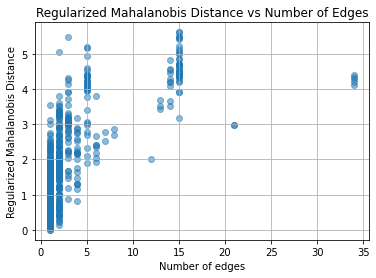

In [59]:
# plot mahalanobis_distance_reg per num_edges
plt.figure(figsize=(6,4))
plt.scatter(orf_pd['num_edges'], orf_pd['mahalanobis_distance_reg'], alpha=0.5)
plt.xlabel('Number of edges')
plt.ylabel('Regularized Mahalanobis Distance')
plt.title('Regularized Mahalanobis Distance vs Number of Edges')
plt.grid(True)
plt.show()

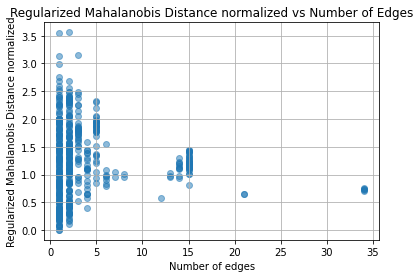

In [60]:
# plot mahalanobis_distance_reg per num_edges
plt.figure(figsize=(6,4))
plt.scatter(orf_pd['num_edges'], orf_pd['normalized_mahal_distance_reg'], alpha=0.5)
plt.xlabel('Number of edges')
plt.ylabel('Regularized Mahalanobis Distance normalized')
plt.title('Regularized Mahalanobis Distance normalized vs Number of Edges')
plt.grid(True)
plt.show()

In [61]:
orf_pd

,db_orf_id,db_mut_id,euclid_distance,max_perturbation,max_relative_perturbation,max_perturbation_abs,max_perturbation_fold,max_perturbation_fold_abs,max_log2_fold_change,max_log2_fold_change_abs,...,min_edge_value,min_relative_edge_value,no_edges_perturbed,inconclusive,mean_wt,log2fc_perturbed,log2fc_no_perturbed,fraction_log2fc_perturbed,normalized_euclid_distance,normalized_mahal_distance_reg
0,9866,216927,0.233343,0.188596,-0.469896,0.188596,5.174751,5.174751,2.371490,2.371490,...,0.045175,0.193246,False,False,0.263096,False,False,0.500000,0.164999,1.563276
1,9866,216928,0.286929,0.230084,-0.733341,0.230084,4.690973,4.690973,2.229887,2.229887,...,0.062337,0.213175,False,False,0.263096,True,False,1.000000,0.202890,1.852960
2,5442,215414,0.419758,0.097175,1.576256,0.097175,1.168243,1.168243,0.224340,0.224340,...,0.468594,0.855986,True,False,0.508444,False,True,0.000000,0.209879,1.000000
3,513,213754,0.311514,0.249961,0.649105,0.249961,2.793063,2.793063,1.481848,1.481848,...,0.139404,0.358030,False,False,0.319614,False,False,0.333333,0.179853,1.517528
4,513,213753,0.099623,0.040162,0.228436,0.040162,1.115009,1.115009,0.157055,0.157055,...,0.349203,0.896854,True,False,0.319614,False,True,0.000000,0.057518,0.903880
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
477,3732,201253,0.273213,0.273213,-0.865118,0.273213,7.413887,7.413887,2.890230,2.890230,...,0.042597,0.134882,False,False,0.315811,True,False,1.000000,0.273213,2.535135
478,3732,201252,0.015482,0.015482,-0.049022,0.015482,1.051549,1.051549,0.072516,0.072516,...,0.300329,0.950978,True,False,0.315811,False,True,0.000000,0.015482,0.143653
479,3732,201258,0.039706,-0.039706,0.125728,0.039706,0.888314,0.888314,-0.170858,0.170858,...,0.355517,1.125728,True,False,0.315811,False,True,0.000000,0.039706,0.368431
480,5132,215357,0.037457,0.037457,-0.089437,0.037457,1.098222,1.098222,0.135170,0.135170,...,0.381348,0.910563,True,False,0.418805,False,True,0.000000,0.037457,0.286549


In [62]:
# correlation between euclidean and mahalanobis
valid_ef = orf_pd[['normalized_euclid_distance', 'normalized_mahal_distance_reg']].dropna()
correlation, p_value = pearsonr(valid_ef['normalized_euclid_distance'], valid_ef['normalized_mahal_distance_reg'])
correlation, p_value

(0.7394675203817145, 1.5783299565340623e-84)

In [63]:
orf_mahal = orf_pd[~orf_pd['mahalanobis_distance'].isnull()]
orf_no_mahal = orf_pd[orf_pd['mahalanobis_distance'].isnull()]

In [64]:
orf_mahal

,db_orf_id,db_mut_id,euclid_distance,max_perturbation,max_relative_perturbation,max_perturbation_abs,max_perturbation_fold,max_perturbation_fold_abs,max_log2_fold_change,max_log2_fold_change_abs,...,min_edge_value,min_relative_edge_value,no_edges_perturbed,inconclusive,mean_wt,log2fc_perturbed,log2fc_no_perturbed,fraction_log2fc_perturbed,normalized_euclid_distance,normalized_mahal_distance_reg
3,513,213754,0.311514,0.249961,0.649105,0.249961,2.793063,2.793063,1.481848,1.481848,...,0.139404,0.358030,False,False,0.319614,False,False,0.333333,0.179853,1.517528
4,513,213753,0.099623,0.040162,0.228436,0.040162,1.115009,1.115009,0.157055,0.157055,...,0.349203,0.896854,True,False,0.319614,False,True,0.000000,0.057518,0.903880
65,4692,215210,0.410129,-0.193214,1.204330,0.193214,0.697800,0.697800,-0.519115,0.519115,...,0.639357,1.433076,True,False,0.373265,False,True,0.000000,0.290005,1.414214
95,14973,218587,0.171429,0.144810,0.527810,0.144810,1.545253,1.545253,0.627843,0.627843,...,0.265583,0.647143,False,False,0.292112,False,True,0.000000,0.121219,1.414214
183,71077,220314,0.113047,0.109253,0.061778,0.109253,1.300422,1.300422,0.378980,0.378980,...,0.363665,0.768981,True,False,0.471527,False,True,0.000000,0.079937,1.414214
361,54175,218808,0.319907,0.316190,-0.107986,0.316190,1.774092,1.774092,0.827081,0.827081,...,0.401656,0.563669,False,False,0.587468,False,True,0.000000,0.226208,1.414214
405,2455,200621,0.456158,0.437054,0.174666,0.437054,3.977664,3.977664,1.991921,1.991921,...,0.139092,0.251404,False,False,0.373790,False,False,0.250000,0.228079,1.378939
406,2455,200617,0.326706,0.207844,1.460565,0.207844,1.552797,1.552797,0.634869,0.634869,...,0.375987,0.643999,False,False,0.373790,False,True,0.000000,0.163353,1.095494
407,2455,200620,0.157695,0.130662,0.130401,0.130662,6.900925,6.900925,2.786790,2.786790,...,0.022143,0.144908,False,False,0.373790,False,False,0.250000,0.078847,0.576074


In [65]:
orf_mahal.num_edges.describe()

count    9.000000
mean     2.888889
std      0.927961
min      2.000000
25%      2.000000
50%      3.000000
75%      4.000000
max      4.000000
Name: num_edges, dtype: float64

In [66]:
orf_no_mahal.num_edges.describe()

count    473.000000
mean       3.917548
std        5.299061
min        1.000000
25%        1.000000
50%        2.000000
75%        4.000000
max       34.000000
Name: num_edges, dtype: float64

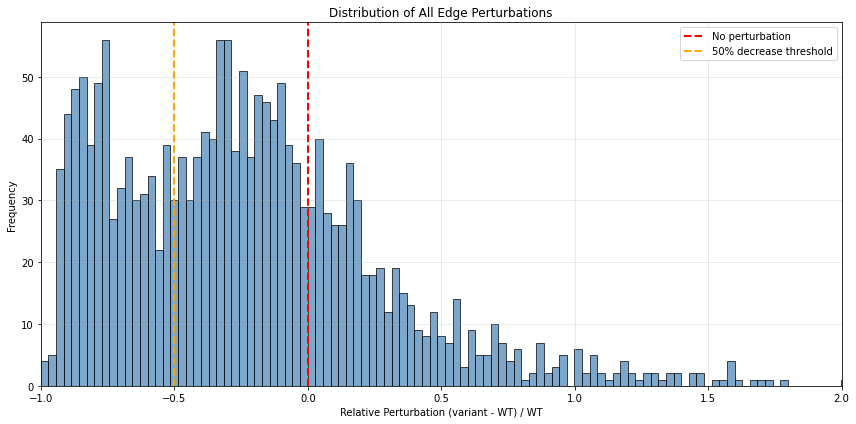

Total number of edge perturbations: 1879
Mean perturbation: -0.075
Median perturbation: -0.263
Std deviation: 1.170
Min perturbation: -1.000
Max perturbation: 13.280
Number of severely perturbed edges (≤50% decrease): 595
Percentage of severely perturbed edges: 31.67%


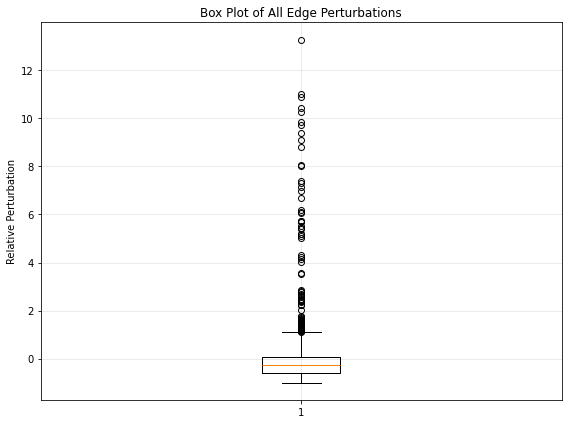

In [67]:
# Plot all_perturbations distribution
import matplotlib.pyplot as plt
import numpy as np

# Flatten all perturbations into a single list
flattened_perturbations = [val for sublist in all_perturbations for val in sublist]

# Create histogram
plt.figure(figsize=(12, 6))
plt.hist(flattened_perturbations, bins=500, alpha=0.7, color='steelblue', edgecolor='black')
plt.axvline(0, color='red', linestyle='--', linewidth=2, label='No perturbation')
plt.xlim(-1, 2)  # Set x-axis limits
plt.axvline(-0.5, color='orange', linestyle='--', linewidth=2, label='50% decrease threshold')
plt.xlabel('Relative Perturbation (variant - WT) / WT')
plt.ylabel('Frequency')
plt.title('Distribution of All Edge Perturbations')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Print summary statistics
print(f"Total number of edge perturbations: {len(flattened_perturbations)}")
print(f"Mean perturbation: {np.mean(flattened_perturbations):.3f}")
print(f"Median perturbation: {np.median(flattened_perturbations):.3f}")
print(f"Std deviation: {np.std(flattened_perturbations):.3f}")
print(f"Min perturbation: {np.min(flattened_perturbations):.3f}")
print(f"Max perturbation: {np.max(flattened_perturbations):.3f}")

# Count severe perturbations (<=50% decrease)
severe_count = sum(1 for x in flattened_perturbations if x <= -0.5)
print(f"Number of severely perturbed edges (≤50% decrease): {severe_count}")
print(f"Percentage of severely perturbed edges: {(severe_count/len(flattened_perturbations))*100:.2f}%")

# Box plot for better visualization of distribution
plt.figure(figsize=(8, 6))
plt.boxplot(flattened_perturbations, vert=True)
plt.ylabel('Relative Perturbation')
plt.title('Box Plot of All Edge Perturbations')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

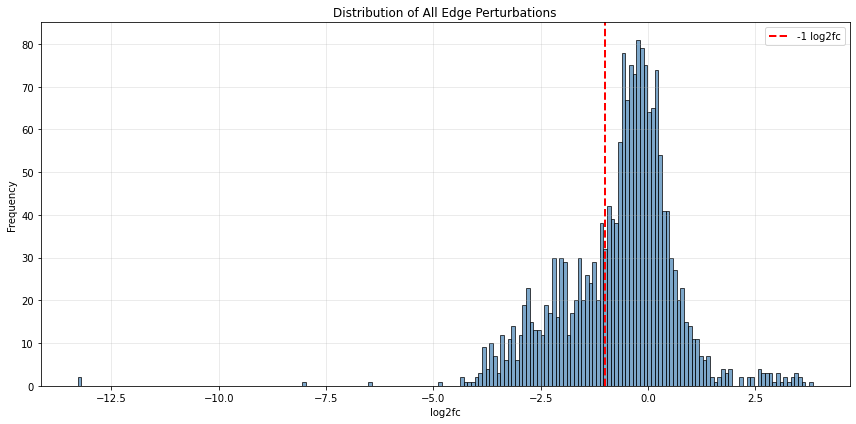

Total number of edge perturbations: 1879
Mean perturbation: -0.681
Median perturbation: -0.440
Std deviation: 1.345
Min perturbation: -13.288
Max perturbation: 3.836
Number of severely perturbed edges (≤50% decrease): 892
Percentage of severely perturbed edges: 47.47%


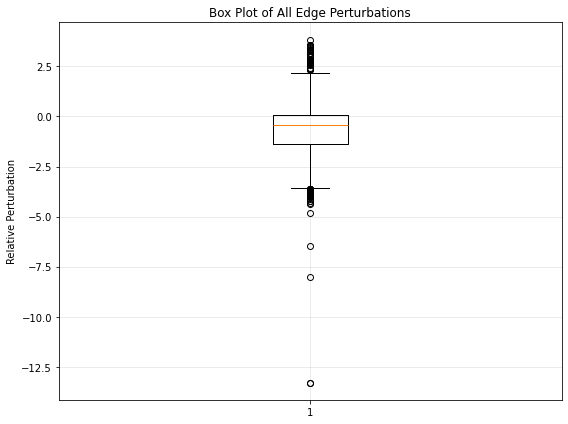

In [68]:
# Plot all_perturbations distribution
import matplotlib.pyplot as plt
import numpy as np

# Flatten all perturbations into a single list
flattened_perturbations = [val for sublist in all_log2s for val in sublist if np.isfinite(val)]

# Create histogram
plt.figure(figsize=(12, 6))
plt.hist(flattened_perturbations, bins=200, alpha=0.7, color='steelblue', edgecolor='black')
plt.axvline(-1, color='red', linestyle='--', linewidth=2, label='-1 log2fc')
# plt.xlim(-1, 2)  # Set x-axis limits
# plt.axvline(-0.5, color='orange', linestyle='--', linewidth=2, label='50% decrease threshold')
plt.xlabel('log2fc')
plt.ylabel('Frequency')
plt.title('Distribution of All Edge Perturbations')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Print summary statistics
print(f"Total number of edge perturbations: {len(flattened_perturbations)}")
print(f"Mean perturbation: {np.mean(flattened_perturbations):.3f}")
print(f"Median perturbation: {np.median(flattened_perturbations):.3f}")
print(f"Std deviation: {np.std(flattened_perturbations):.3f}")
print(f"Min perturbation: {np.min(flattened_perturbations):.3f}")
print(f"Max perturbation: {np.max(flattened_perturbations):.3f}")

# Count severe perturbations (<=50% decrease)
severe_count = sum(1 for x in flattened_perturbations if x <= -0.5)
print(f"Number of severely perturbed edges (≤50% decrease): {severe_count}")
print(f"Percentage of severely perturbed edges: {(severe_count/len(flattened_perturbations))*100:.2f}%")

# Box plot for better visualization of distribution
plt.figure(figsize=(8, 6))
plt.boxplot(flattened_perturbations, vert=True)
plt.ylabel('Relative Perturbation')
plt.title('Box Plot of All Edge Perturbations')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [69]:
orf_distances

db_orf_id,db_mut_id,euclid_distance,max_perturbation,max_relative_perturbation,max_perturbation_abs,max_perturbation_fold,max_perturbation_fold_abs,max_log2_fold_change,max_log2_fold_change_abs,mahalanobis_distance,mahalanobis_distance_reg,num_edges,all_edges_severely_perturbed,fraction_severely_perturbed,mean_perturbation,mean_relative_perturbation,std_relative_perturbation,min_edge_value,min_relative_edge_value,no_edges_perturbed,inconclusive,mean_wt,log2fc_perturbed,log2fc_no_perturbed,fraction_log2fc_perturbed,normalized_euclid_distance,normalized_mahal_distance_reg
str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,i64,bool,f64,f64,f64,f64,f64,f64,bool,bool,f64,bool,bool,f64,f64,f64
"""9866""","""216927""",0.233343,0.188596,-0.469896,0.188596,5.174751,5.174751,2.37149,2.37149,null,2.210806,2,false,0.5,-0.163002,-0.638325,0.238195,0.045175,0.193246,false,false,0.263096,false,false,0.5,0.164999,1.563276
"""9866""","""216928""",0.286929,0.230084,-0.733341,0.230084,4.690973,4.690973,2.229887,2.229887,null,2.620482,2,true,1.0,-0.200759,-0.760083,0.037818,0.062337,0.213175,false,false,0.263096,true,false,1.0,0.20289,1.85296
"""5442""","""215414""",0.419758,0.097175,1.576256,0.097175,1.168243,1.168243,0.22434,0.22434,null,2.0,4,false,0.0,0.091664,0.465683,0.812821,0.468594,0.855986,true,false,0.508444,false,true,0.0,0.209879,1.0
"""513""","""213754""",0.311514,0.249961,0.649105,0.249961,2.793063,2.793063,1.481848,1.481848,6.244787,2.628435,3,false,0.333333,-0.015961,0.022249,0.646348,0.139404,0.35803,false,false,0.319614,false,false,0.333333,0.179853,1.517528
"""513""","""213753""",0.099623,0.040162,0.228436,0.040162,1.115009,1.115009,0.157055,0.157055,0.752148,1.565566,3,false,0.0,0.029589,0.116553,0.190276,0.349203,0.896854,true,false,0.319614,false,true,0.0,0.057518,0.90388
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""3732""","""201253""",0.273213,0.273213,-0.865118,0.273213,7.413887,7.413887,2.89023,2.89023,null,2.535135,1,true,1.0,-0.273213,-0.865118,null,0.042597,0.134882,false,false,0.315811,true,false,1.0,0.273213,2.535135
"""3732""","""201252""",0.015482,0.015482,-0.049022,0.015482,1.051549,1.051549,0.072516,0.072516,null,0.143653,1,false,0.0,-0.015482,-0.049022,null,0.300329,0.950978,true,false,0.315811,false,true,0.0,0.015482,0.143653
"""3732""","""201258""",0.039706,-0.039706,0.125728,0.039706,0.888314,0.888314,-0.170858,0.170858,null,0.368431,1,false,0.0,0.039706,0.125728,null,0.355517,1.125728,true,false,0.315811,false,true,0.0,0.039706,0.368431


In [70]:
orf_pd = orf_distances.to_pandas()
orf_pd

,db_orf_id,db_mut_id,euclid_distance,max_perturbation,max_relative_perturbation,max_perturbation_abs,max_perturbation_fold,max_perturbation_fold_abs,max_log2_fold_change,max_log2_fold_change_abs,...,min_edge_value,min_relative_edge_value,no_edges_perturbed,inconclusive,mean_wt,log2fc_perturbed,log2fc_no_perturbed,fraction_log2fc_perturbed,normalized_euclid_distance,normalized_mahal_distance_reg
0,9866,216927,0.233343,0.188596,-0.469896,0.188596,5.174751,5.174751,2.371490,2.371490,...,0.045175,0.193246,False,False,0.263096,False,False,0.500000,0.164999,1.563276
1,9866,216928,0.286929,0.230084,-0.733341,0.230084,4.690973,4.690973,2.229887,2.229887,...,0.062337,0.213175,False,False,0.263096,True,False,1.000000,0.202890,1.852960
2,5442,215414,0.419758,0.097175,1.576256,0.097175,1.168243,1.168243,0.224340,0.224340,...,0.468594,0.855986,True,False,0.508444,False,True,0.000000,0.209879,1.000000
3,513,213754,0.311514,0.249961,0.649105,0.249961,2.793063,2.793063,1.481848,1.481848,...,0.139404,0.358030,False,False,0.319614,False,False,0.333333,0.179853,1.517528
4,513,213753,0.099623,0.040162,0.228436,0.040162,1.115009,1.115009,0.157055,0.157055,...,0.349203,0.896854,True,False,0.319614,False,True,0.000000,0.057518,0.903880
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
477,3732,201253,0.273213,0.273213,-0.865118,0.273213,7.413887,7.413887,2.890230,2.890230,...,0.042597,0.134882,False,False,0.315811,True,False,1.000000,0.273213,2.535135
478,3732,201252,0.015482,0.015482,-0.049022,0.015482,1.051549,1.051549,0.072516,0.072516,...,0.300329,0.950978,True,False,0.315811,False,True,0.000000,0.015482,0.143653
479,3732,201258,0.039706,-0.039706,0.125728,0.039706,0.888314,0.888314,-0.170858,0.170858,...,0.355517,1.125728,True,False,0.315811,False,True,0.000000,0.039706,0.368431
480,5132,215357,0.037457,0.037457,-0.089437,0.037457,1.098222,1.098222,0.135170,0.135170,...,0.381348,0.910563,True,False,0.418805,False,True,0.000000,0.037457,0.286549


In [71]:
orf_distances.filter(pl.col("all_edges_severely_perturbed") == True)

db_orf_id,db_mut_id,euclid_distance,max_perturbation,max_relative_perturbation,max_perturbation_abs,max_perturbation_fold,max_perturbation_fold_abs,max_log2_fold_change,max_log2_fold_change_abs,mahalanobis_distance,mahalanobis_distance_reg,num_edges,all_edges_severely_perturbed,fraction_severely_perturbed,mean_perturbation,mean_relative_perturbation,std_relative_perturbation,min_edge_value,min_relative_edge_value,no_edges_perturbed,inconclusive,mean_wt,log2fc_perturbed,log2fc_no_perturbed,fraction_log2fc_perturbed,normalized_euclid_distance,normalized_mahal_distance_reg
str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,i64,bool,f64,f64,f64,f64,f64,f64,bool,bool,f64,bool,bool,f64,f64,f64
"""9866""","""216928""",0.286929,0.230084,-0.733341,0.230084,4.690973,4.690973,2.229887,2.229887,null,2.620482,2,true,1.0,-0.200759,-0.760083,0.037818,0.062337,0.213175,false,false,0.263096,true,false,1.0,0.20289,1.85296
"""71337""","""3950""",0.632821,0.584044,-0.621766,0.584044,7.999623,7.999623,2.999932,2.999932,null,3.075159,3,true,1.0,-0.307881,-0.766773,0.13056,0.048621,0.125006,false,false,0.380434,true,false,1.0,0.36536,1.775444
"""71337""","""205774""",0.650732,0.603181,-0.679564,0.603181,10.380368,10.380368,3.375786,3.375786,null,3.135624,3,true,1.0,-0.316131,-0.78847,0.112183,0.049295,0.096336,false,false,0.380434,true,false,1.0,0.3757,1.810353
"""71337""","""3957""",0.656321,0.606982,-0.739989,0.606982,11.032541,11.032541,3.463693,3.463693,null,3.159942,3,true,1.0,-0.319932,-0.799679,0.095109,0.056648,0.090641,false,false,0.380434,true,false,1.0,0.378927,1.824393
"""71337""","""205769""",0.642344,0.597425,-0.664966,0.597425,9.527623,9.527623,3.252116,3.252116,null,3.096407,3,true,1.0,-0.310376,-0.769098,0.116579,0.057192,0.104958,false,false,0.380434,true,false,1.0,0.370858,1.787711
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""8999""","""203008""",0.166962,0.166962,-0.733499,0.166962,3.752331,3.752331,1.907787,1.907787,null,1.225561,1,true,1.0,-0.166962,-0.733499,null,0.060662,0.266501,false,false,0.227623,true,false,1.0,0.166962,1.225561
"""8999""","""203000""",0.145273,0.145273,-0.638218,0.145273,2.764094,2.764094,1.466807,1.466807,null,1.066361,1,true,1.0,-0.145273,-0.638218,null,0.08235,0.361782,false,false,0.227623,true,false,1.0,0.145273,1.066361
"""8999""","""203012""",0.18423,0.18423,-0.809362,0.18423,5.245543,5.245543,2.391092,2.391092,null,1.352316,1,true,1.0,-0.18423,-0.809362,null,0.043394,0.190638,false,false,0.227623,true,false,1.0,0.18423,1.352316


In [72]:
orf_distances.filter(pl.col("db_orf_id") == '100016069')

db_orf_id,db_mut_id,euclid_distance,max_perturbation,max_relative_perturbation,max_perturbation_abs,max_perturbation_fold,max_perturbation_fold_abs,max_log2_fold_change,max_log2_fold_change_abs,mahalanobis_distance,mahalanobis_distance_reg,num_edges,all_edges_severely_perturbed,fraction_severely_perturbed,mean_perturbation,mean_relative_perturbation,std_relative_perturbation,min_edge_value,min_relative_edge_value,no_edges_perturbed,inconclusive,mean_wt,log2fc_perturbed,log2fc_no_perturbed,fraction_log2fc_perturbed,normalized_euclid_distance,normalized_mahal_distance_reg
str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,i64,bool,f64,f64,f64,f64,f64,f64,bool,bool,f64,bool,bool,f64,f64,f64
"""100016069""","""2609""",0.584785,0.46106,-0.83752,0.46106,8.034861,8.034861,3.006273,3.006273,null,3.221958,2,true,1.0,-0.410389,-0.856531,0.026886,0.051134,0.124458,false,false,0.480679,true,false,1.0,0.413506,2.278268
"""100016069""","""2622""",0.584226,0.476994,-0.821072,0.476994,7.488575,7.488575,2.904691,2.904691,null,3.257266,2,true,1.0,-0.407166,-0.843768,0.032096,0.073513,0.133537,false,false,0.480679,true,false,1.0,0.413111,2.303235
"""100016069""","""2626""",0.600157,0.488418,-0.848878,0.488418,8.866473,8.866473,3.14836,3.14836,null,3.341518,2,true,1.0,-0.418591,-0.868047,0.027108,0.062089,0.112784,false,false,0.480679,true,false,1.0,0.424375,2.36281
"""100016069""","""2660""",0.417375,0.356576,-0.52798,0.356576,2.838682,2.838682,1.505221,1.505221,null,2.388022,2,true,1.0,-0.286749,-0.587852,0.084672,0.19393,0.352276,false,false,0.480679,true,false,1.0,0.295128,1.688586
"""100016069""","""2644""",0.099618,0.060552,0.192534,0.060552,1.123586,1.123586,0.168111,0.168111,null,1.019359,2,false,0.0,0.009276,0.041271,0.213919,0.489955,0.890007,true,false,0.480679,false,true,0.0,0.070441,0.720796
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""100016069""","""2659""",0.531921,0.404532,-0.734836,0.404532,6.276117,6.276117,2.649872,2.649872,null,2.912056,2,true,1.0,-0.374961,-0.787751,0.074833,0.065463,0.159334,false,false,0.480679,true,false,1.0,0.376125,2.059135
"""100016069""","""2641""",0.333734,0.295246,-0.378704,0.295246,2.156644,2.156644,1.108788,1.108788,null,1.967855,2,false,0.5,-0.225418,-0.45751,0.111449,0.255261,0.463683,false,false,0.480679,false,false,0.5,0.235986,1.391484
"""100016069""","""2656""",0.494007,0.352449,-0.640227,0.352449,6.350245,6.350245,2.666812,2.666812,null,2.704008,2,true,1.0,-0.349301,-0.741376,0.143047,0.064699,0.157474,false,false,0.480679,true,false,1.0,0.349315,1.912022


In [73]:
orf_distances = orf_distances.with_columns(
    (pl.col("normalized_euclid_distance") / pl.col("normalized_euclid_distance").max()).alias("normalized_euclid_distance_normalized"),
)

In [74]:
orf_distances

db_orf_id,db_mut_id,euclid_distance,max_perturbation,max_relative_perturbation,max_perturbation_abs,max_perturbation_fold,max_perturbation_fold_abs,max_log2_fold_change,max_log2_fold_change_abs,mahalanobis_distance,mahalanobis_distance_reg,num_edges,all_edges_severely_perturbed,fraction_severely_perturbed,mean_perturbation,mean_relative_perturbation,std_relative_perturbation,min_edge_value,min_relative_edge_value,no_edges_perturbed,inconclusive,mean_wt,log2fc_perturbed,log2fc_no_perturbed,fraction_log2fc_perturbed,normalized_euclid_distance,normalized_mahal_distance_reg,normalized_euclid_distance_normalized
str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,i64,bool,f64,f64,f64,f64,f64,f64,bool,bool,f64,bool,bool,f64,f64,f64,f64
"""9866""","""216927""",0.233343,0.188596,-0.469896,0.188596,5.174751,5.174751,2.37149,2.37149,null,2.210806,2,false,0.5,-0.163002,-0.638325,0.238195,0.045175,0.193246,false,false,0.263096,false,false,0.5,0.164999,1.563276,0.208022
"""9866""","""216928""",0.286929,0.230084,-0.733341,0.230084,4.690973,4.690973,2.229887,2.229887,null,2.620482,2,true,1.0,-0.200759,-0.760083,0.037818,0.062337,0.213175,false,false,0.263096,true,false,1.0,0.20289,1.85296,0.255793
"""5442""","""215414""",0.419758,0.097175,1.576256,0.097175,1.168243,1.168243,0.22434,0.22434,null,2.0,4,false,0.0,0.091664,0.465683,0.812821,0.468594,0.855986,true,false,0.508444,false,true,0.0,0.209879,1.0,0.264605
"""513""","""213754""",0.311514,0.249961,0.649105,0.249961,2.793063,2.793063,1.481848,1.481848,6.244787,2.628435,3,false,0.333333,-0.015961,0.022249,0.646348,0.139404,0.35803,false,false,0.319614,false,false,0.333333,0.179853,1.517528,0.226749
"""513""","""213753""",0.099623,0.040162,0.228436,0.040162,1.115009,1.115009,0.157055,0.157055,0.752148,1.565566,3,false,0.0,0.029589,0.116553,0.190276,0.349203,0.896854,true,false,0.319614,false,true,0.0,0.057518,0.90388,0.072515
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""3732""","""201253""",0.273213,0.273213,-0.865118,0.273213,7.413887,7.413887,2.89023,2.89023,null,2.535135,1,true,1.0,-0.273213,-0.865118,null,0.042597,0.134882,false,false,0.315811,true,false,1.0,0.273213,2.535135,0.344453
"""3732""","""201252""",0.015482,0.015482,-0.049022,0.015482,1.051549,1.051549,0.072516,0.072516,null,0.143653,1,false,0.0,-0.015482,-0.049022,null,0.300329,0.950978,true,false,0.315811,false,true,0.0,0.015482,0.143653,0.019518
"""3732""","""201258""",0.039706,-0.039706,0.125728,0.039706,0.888314,0.888314,-0.170858,0.170858,null,0.368431,1,false,0.0,0.039706,0.125728,null,0.355517,1.125728,true,false,0.315811,false,true,0.0,0.039706,0.368431,0.050059


In [75]:
# append metadata and write out scores
metadata = pl.read_csv(f"{meta_outputs}/slim_metadata.csv").rename({
    "orf_id": "db_orf_id",
    "mut_id": "db_mut_id"
}).with_columns(
    pl.col("db_orf_id").cast(pl.String).alias("db_orf_id"),
    pl.col("db_mut_id").cast(pl.String).alias("db_mut_id")
)

orf_distances = orf_distances.join(metadata, on=["db_orf_id", "db_mut_id"], how="left")


orf_distances.write_csv(f"{outputs_dir}/5_variant_perturbation_scores_automated_summed.csv")

In [ ]:
# Drop alleles that were tested multiple times, keep only one (the one with the highest db_mut_id, which should be the most recent)
# Cast to int for sorting
orf_distances = orf_distances.with_columns(
    pl.col("db_mut_id").cast(pl.Int64).alias("db_mut_id"),
    pl.col("db_orf_id").cast(pl.Int64).alias("db_orf_id")
)

orf_distances = orf_distances.sort("db_mut_id", descending=True).unique(subset=["allele_0"], keep="first")

In [78]:
orf_distances

db_orf_id,db_mut_id,euclid_distance,max_perturbation,max_relative_perturbation,max_perturbation_abs,max_perturbation_fold,max_perturbation_fold_abs,max_log2_fold_change,max_log2_fold_change_abs,mahalanobis_distance,mahalanobis_distance_reg,num_edges,all_edges_severely_perturbed,fraction_severely_perturbed,mean_perturbation,mean_relative_perturbation,std_relative_perturbation,min_edge_value,min_relative_edge_value,no_edges_perturbed,inconclusive,mean_wt,log2fc_perturbed,log2fc_no_perturbed,fraction_log2fc_perturbed,normalized_euclid_distance,normalized_mahal_distance_reg,normalized_euclid_distance_normalized,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0
str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,i64,bool,f64,f64,f64,f64,f64,f64,bool,bool,f64,bool,bool,f64,f64,f64,f64,str,str,str,str,str,str,f64,f64,str
"""6983""","""216123""",0.252393,0.249015,0.207527,0.249015,4.060517,4.060517,2.021663,2.021663,null,2.851467,2,false,0.5,-0.103928,-0.2731,0.679708,0.081364,0.246274,false,false,0.264352,false,false,0.5,0.178469,2.016291,0.225004,"""PITX2""","""Arg137Trp""","""409C>T""","""ENSG00000164093""","""CEGS2""","""1_Pathogenic""",null,null,"""PITX2_Arg137Trp"""
"""14910""","""218498""",0.570638,0.570638,-0.721368,0.570638,3.588969,3.588969,1.84357,1.84357,null,1.987033,1,true,1.0,-0.570638,-0.721368,null,0.220411,0.278632,false,false,0.791049,true,false,1.0,0.570638,1.987033,0.719431,"""HGD""","""Val300Gly""","""899T>G""","""ENSG00000113924""","""CEGS2""","""1_Pathogenic""",null,2.0,"""HGD_Val300Gly"""
"""5585""","""215440""",0.035918,-0.035918,0.067875,0.035918,0.936439,0.936439,-0.094743,0.094743,null,0.63597,1,false,0.0,0.035918,0.067875,null,0.5651,1.067875,true,false,0.529182,false,true,0.0,0.035918,0.63597,0.045284,"""CRYAB""","""Gly154Ser""","""460G>A""","""ENSG00000109846""","""CEGS2""","""3_Conflicting""",null,1.0,"""CRYAB_Gly154Ser"""
"""11805""","""2134""",0.029791,0.021494,0.045054,0.021494,1.077117,1.077117,0.107175,0.107175,null,0.317041,2,false,0.0,-0.000432,-0.013271,0.082484,0.278715,0.928404,true,false,0.37904,false,true,0.0,0.021066,0.224182,0.026559,"""SMAD3""","""Ile170Val""","""508A>G""","""ENSG00000166949""","""RC4""","""2_Benign""",0.0506272,2.0,"""SMAD3_Ile170Val"""
"""100016069""","""2635""",0.546561,0.430426,-0.781873,0.430426,5.551235,5.551235,2.472809,2.472809,null,3.010482,2,true,1.0,-0.383634,-0.800867,0.026861,0.074011,0.18014,false,false,0.480679,true,false,1.0,0.386477,2.128732,0.48725,"""KCNJ2""","""Ile258Thr""","""773T>C""","""ENSG00000123700""","""Edgotyping3""","""2_Benign""",null,1.0,"""KCNJ2_Ile258Thr"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""100016069""","""2649""",0.495187,0.412944,-0.665178,0.412944,4.001877,4.001877,2.000677,2.000677,null,2.789803,2,true,1.0,-0.343117,-0.707648,0.060061,0.137562,0.249883,false,false,0.480679,true,false,1.0,0.35015,1.972688,0.441451,"""KCNJ2""","""Arg312His""","""935G>A""","""ENSG00000123700""","""Edgotyping3""","""1_Pathogenic""",6.8405e-7,2.0,"""KCNJ2_Arg312His"""
"""7675""","""202586""",0.279316,0.214831,-0.071645,0.214831,1.95918,1.95918,0.97025,0.97025,null,1.663122,3,false,0.0,-0.14647,-0.270494,0.209702,0.223973,0.510418,false,false,0.626837,false,true,0.0,0.161263,0.960204,0.203312,"""NMNAT1""","""Arg207Trp""","""619C>T""","""ENSG00000173614""","""CEGS2""","""1_Pathogenic""",0.000023,2.0,"""NMNAT1_Arg207Trp"""
"""4043""","""201419""",0.215317,0.162404,-0.046328,0.162404,2.132697,2.132697,1.092679,1.092679,null,2.045272,6,false,0.333333,-0.073574,-0.283187,0.209573,0.087021,0.46889,false,false,0.304669,false,false,0.333333,0.087903,0.834979,0.110823,"""COQ8A""","""Gly549Ser""","""1645G>A""","""ENSG00000163050""","""CEGS2""","""4_VUS""",0.000086,2.0,"""COQ8A_Gly549Ser"""


In [ ]:
# Characterize variants based on perturbation patterns
orf_distances = orf_distances.with_columns(
    pl.when(pl.col("all_edges_severely_perturbed") == True)
    .then(pl.lit("QN"))  # Quasi-null: all edges severely perturbed
    .when(pl.col("no_edges_perturbed") == True)
    .then(pl.lit("QW"))  # Wild-type like: no edges perturbed
    .when(pl.col("inconclusive") == True)
    .then(pl.lit("I"))   # Inconclusive: all edges moderately perturbed
    .otherwise(pl.lit("E"))  # Edgetic: some but not all edges perturbed
    .alias("variant_class")
)

# orf_distances.write_csv(f"{outputs_dir}/6_variants_perturbation_scores_automated_annotated.csv")

In [ ]:
# Characterize variants based on perturbation patterns
orf_distances = orf_distances.with_columns(
    pl.when(pl.col("log2fc_perturbed") == True)
    .then(pl.lit("QN"))  # Quasi-null: all edges severely perturbed
    .when(pl.col("log2fc_no_perturbed") == True)
    .then(pl.lit("QW"))  # Wild-type like: no edges perturbed
    .otherwise(pl.lit("E"))  # Edgetic: some but not all edges perturbed
    .alias("variant_class_log2fc")
)

orf_distances.write_csv(f"{outputs_dir}/6_variants_perturbation_scores_automated_annotated.csv")

In [ ]:
orf_distances_pd = orf_distances.to_pandas()
orf_distances_pd

,db_orf_id,db_mut_id,euclid_distance,max_perturbation,max_relative_perturbation,max_perturbation_abs,max_perturbation_fold,max_perturbation_fold_abs,max_log2_fold_change,max_log2_fold_change_abs,...,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,variant_class,variant_class_log2fc
0,54308,3142,0.035523,0.035523,-0.088319,0.035523,1.096875,1.096875,0.133399,0.133399,...,Asp26Asn,76G>A,ENSG00000057294,Edgotyping3,2_Benign,NaN,2.0,PKP2_Asp26Asn,QW,QW
1,3689,214851,0.336779,0.336779,-0.664435,0.336779,2.980051,2.980051,1.575337,1.575337,...,Gly299Arg,895G>C,ENSG00000106633,CEGS2,1_Pathogenic,NaN,2.0,GCK_Gly299Arg,QN,QN
2,8999,202990,0.112924,0.112924,-0.496102,0.112924,1.984527,1.984527,0.988795,0.988795,...,Val50Gly,149T>G,ENSG00000118271,CEGS2,1_Pathogenic,NaN,1.0,TTR_Val50Gly,I,QW
3,11805,2140,0.426794,0.365720,-0.732844,0.365720,4.968626,4.968626,2.312847,2.312847,...,Glu239Lys,715G>A,ENSG00000166949,Edgotyping3,1_Pathogenic,NaN,2.0,SMAD3_Glu239Lys,QN,QN
4,281,744,0.071094,0.071094,-0.364746,0.071094,1.574175,1.574175,0.654596,0.654596,...,Asn205Asp,613A>G,ENSG00000110921,RC4,1_Pathogenic,0.000027,2.0,MVK_Asn205Asp,I,QW
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
470,12739,203835,0.063740,-0.063740,1.087950,0.063740,0.478939,0.478939,-1.062087,1.062087,...,Ser47Arg,141C>A,ENSG00000065135,CEGS2,1_Pathogenic,NaN,NaN,GNAI3_Ser47Arg,QW,QW
471,70497,3872,0.397021,0.397021,-0.859629,0.397021,7.123992,7.123992,2.832686,2.832686,...,Arg289Cys,865C>T,ENSG00000172482,Edgotyping3,4_VUS,0.000456,2.0,AGXT_Arg289Cys,QN,QN
472,6983,216125,0.255858,0.251423,-0.239168,0.251423,4.184375,4.184375,2.065012,2.065012,...,Arg144Pro,431G>C,ENSG00000164093,CEGS2,1_Pathogenic,NaN,2.0,PITX2_Arg144Pro,E,E
473,2651,214302,0.140259,0.140259,-0.663532,0.140259,2.972055,2.972055,1.571461,1.571461,...,Gly123Asp,368G>A,ENSG00000128973,CEGS2,3_Conflicting,NaN,1.0,CLN6_Gly123Asp,QN,QN


In [ ]:
orf_distances_pd[(orf_distances_pd.variant_class == 'E') & (orf_distances_pd.variant_class_log2fc != 'E')]

,db_orf_id,db_mut_id,euclid_distance,max_perturbation,max_relative_perturbation,max_perturbation_abs,max_perturbation_fold,max_perturbation_fold_abs,max_log2_fold_change,max_log2_fold_change_abs,...,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,variant_class,variant_class_log2fc
9,54175,218808,0.319907,0.316190,-0.107986,0.316190,1.774092,1.774092,0.827081,0.827081,...,Arg107Ser,319C>A,ENSG00000122859,RC4,1_Pathogenic,NaN,2.0,NEUROG3_Arg107Ser,E,QW
15,2713,200824,0.433372,0.271856,0.904326,0.271856,1.593449,1.593449,0.672152,0.672152,...,Ser106Arg,318C>G,ENSG00000076242,CEGS2,4_VUS,NaN,1.0,MLH1_Ser106Arg,E,QW
28,3980,201378,0.176390,0.112260,0.147880,0.112260,1.470060,1.470060,0.555875,0.555875,...,Ala324Thr,970G>A,ENSG00000030582,CEGS2,3_Conflicting,1.303970e-03,1.0,GRN_Ala324Thr,E,QW
60,4723,201749,0.241638,0.221028,-0.220202,0.221028,1.439421,1.439421,0.525489,0.525489,...,Ala277Val,830C>T,ENSG00000140416,CEGS2,4_VUS,NaN,1.0,TPM1_Ala277Val,E,QW
75,7652,1802,0.493987,0.352700,-0.143666,0.352700,1.954187,1.954187,0.966569,0.966569,...,Lys196Arg,587A>G,ENSG00000136854,Edgotyping3,4_VUS,NaN,NaN,STXBP1_Lys196Arg,E,QW
81,13939,204115,0.690422,0.350607,-0.011933,0.350607,1.919669,1.919669,0.940858,0.940858,...,Asn114Asp,340A>G,ENSG00000170442,CEGS2,1_Pathogenic,NaN,NaN,KRT86_Asn114Asp,E,QW
87,7982,202787,0.206918,0.206134,-0.023060,0.206134,1.364067,1.364067,0.447914,0.447914,...,Ser104Arg,312C>A,ENSG00000165704,CEGS2,1_Pathogenic,0.000000e+00,NaN,HPRT1_Ser104Arg,E,QW
97,11805,2139,0.091761,0.084050,-0.080418,0.084050,1.388834,1.388834,0.473874,0.473874,...,Trp232Cys,696G>C,ENSG00000166949,Edgotyping3,4_VUS,NaN,1.0,SMAD3_Trp232Cys,E,QW
103,55855,219414,0.270649,0.266844,0.037864,0.266844,1.523970,1.523970,0.607834,0.607834,...,Asn186Tyr,556A>T,ENSG00000172867,CEGS2,1_Pathogenic,NaN,NaN,KRT2_Asn186Tyr,E,QW
127,7652,1838,0.470103,0.276987,1.325742,0.276987,1.621959,1.621959,0.697737,0.697737,...,Arg505His,1514G>A,ENSG00000136854,Edgotyping3,3_Conflicting,6.156730e-06,1.0,STXBP1_Arg505His,E,QW


In [ ]:
orf_distances_pd.variant_class.value_counts()

variant_class
QW    165
E     158
QN    109
I      43
Name: count, dtype: int64

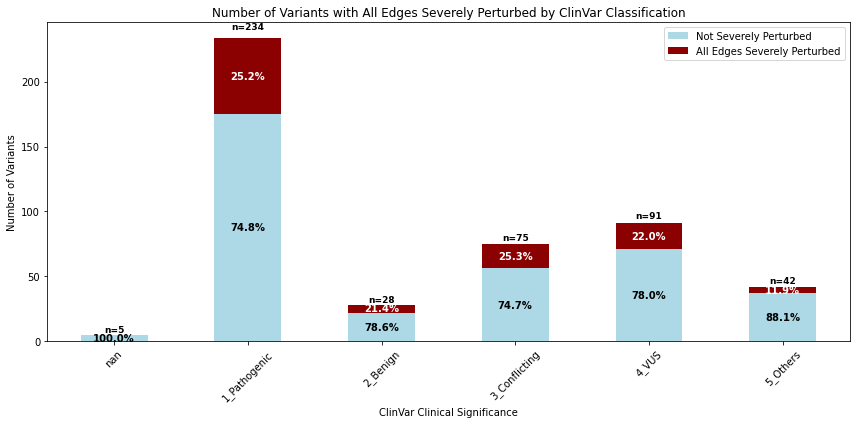

Variant classification summary:
  variant_class  len
0             E  158
1             I   43
2            QN  109
3            QW  165

With percentages:
  variant_class  len  percentage
0             E  158   33.263158
1             I   43    9.052632
2            QN  109   22.947368
3            QW  165   34.736842


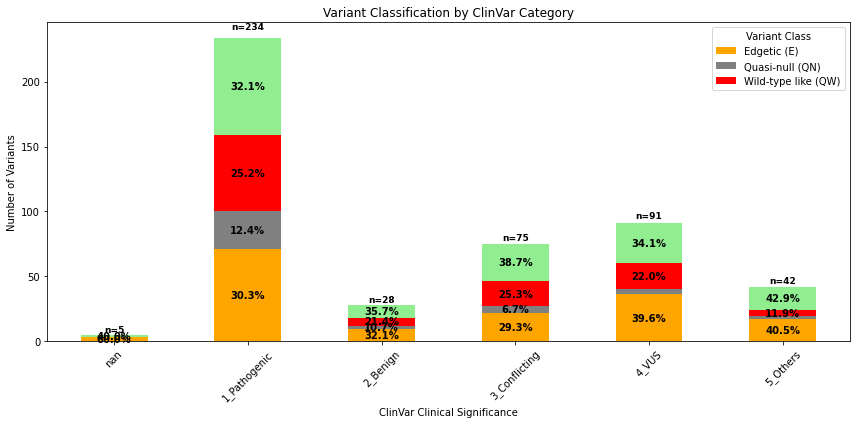


Summary by variant class:

QW variants:
  Count: 165
  Mean fraction severely perturbed: 0.000
  Mean relative perturbation: 0.242
  Mean Euclidean distance: 0.107

E variants:
  Count: 158
  Mean fraction severely perturbed: 0.287
  Mean relative perturbation: -0.191
  Mean Euclidean distance: 0.221

QN variants:
  Count: 109
  Mean fraction severely perturbed: 1.000
  Mean relative perturbation: -0.786
  Mean Euclidean distance: 0.380


In [ ]:
# Plot number of all_edges_severely_perturbed per clinvar_clnsig_clean categories
import matplotlib.pyplot as plt
import seaborn as sns

# Count all_edges_severely_perturbed by clinvar_clnsig_clean
perturbed_counts = orf_distances.group_by(["clinvar_clnsig_clean", "all_edges_severely_perturbed"]).len().sort("clinvar_clnsig_clean")

# Convert to pandas for easier plotting
perturbed_counts_pd = perturbed_counts.to_pandas()

# Create a pivot table for easier plotting
pivot_data = perturbed_counts_pd.pivot(index='clinvar_clnsig_clean', columns='all_edges_severely_perturbed', values='len').fillna(0)
# Create the plot
fig, ax = plt.subplots(figsize=(12, 6))

# Plot stacked bar chart
pivot_data.plot(kind='bar', stacked=True, ax=ax, color=['lightblue', 'darkred'])

# Calculate and add percentage labels
for i, (index, row) in enumerate(pivot_data.iterrows()):
    total = row.sum()
    if total > 0:
        # Calculate percentages
        pct_not_perturbed = (row[False] / total) * 100 if False in row.index else 0
        pct_perturbed = (row[True] / total) * 100 if True in row.index else 0
        
        # Add percentage labels above bars
        if pct_not_perturbed > 5:  # Only show if percentage is > 5% to avoid clutter
            ax.text(i, row[False]/2, f'{pct_not_perturbed:.1f}%', 
                   ha='center', va='center', fontweight='bold', color='black')
        
        if pct_perturbed > 5:  # Only show if percentage is > 5% to avoid clutter
            ax.text(i, row[False] + row[True]/2 if True in row.index else 0, 
                   f'{pct_perturbed:.1f}%', 
                   ha='center', va='center', fontweight='bold', color='white')
        
        # Add total count above the entire bar
        ax.text(i, total + total*0.02, f'n={int(total)}', 
               ha='center', va='bottom', fontsize=9, fontweight='bold')

ax.set_title('Number of Variants with All Edges Severely Perturbed by ClinVar Classification')
ax.set_xlabel('ClinVar Clinical Significance')
ax.set_ylabel('Number of Variants')
ax.legend(['Not Severely Perturbed', 'All Edges Severely Perturbed'])
ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()
# Characterize variants based on perturbation patterns
# orf_distances = orf_distances.with_columns(
#     pl.when(pl.col("all_edges_severely_perturbed") == True)
#     .then(pl.lit("QN"))  # Quasi-null: all edges severely perturbed
#     .when(pl.col("no_edges_perturbed") == True)
#     .then(pl.lit("QW"))  # Wild-type like: no edges perturbed
#     .otherwise(pl.lit("E"))  # Edgetic: some but not all edges perturbed
#     .alias("variant_class")
# )

# Print summary of variant classifications
print("Variant classification summary:")
classification_summary = orf_distances.group_by("variant_class").len().sort("variant_class")
print(classification_summary.to_pandas())

# Create a more detailed summary with percentages
total_variants = orf_distances.shape[0]
classification_with_pct = classification_summary.with_columns(
    (pl.col("len") / total_variants * 100).alias("percentage")
)
print("\nWith percentages:")
print(classification_with_pct.to_pandas())

# Plot variant classifications by ClinVar category
import matplotlib.pyplot as plt
import seaborn as sns

# Count variant classes by ClinVar category
class_counts = orf_distances.group_by(["clinvar_clnsig_clean", "variant_class"]).len().sort(["clinvar_clnsig_clean", "variant_class"])
class_counts_pd = class_counts.to_pandas()

# Create pivot table for plotting
pivot_class_data = class_counts_pd.pivot(index='clinvar_clnsig_clean', columns='variant_class', values='len').fillna(0)

# Plot stacked bar chart
fig, ax = plt.subplots(figsize=(12, 6))
colors = {'QW': 'lightgreen', 'E': 'orange', 'QN': 'red'}
pivot_class_data.plot(kind='bar', stacked=True, ax=ax, 
                     color=[colors.get(x, 'gray') for x in pivot_class_data.columns])

# Add percentage labels
for i, (index, row) in enumerate(pivot_class_data.iterrows()):
    total = row.sum()
    if total > 0:
        cumulative = 0
        for j, (class_type, count) in enumerate(row.items()):
            if count > 0:
                pct = (count / total) * 100
                if pct > 5:  # Only show if percentage > 5%
                    ax.text(i, cumulative + count/2, f'{pct:.1f}%', 
                           ha='center', va='center', fontweight='bold')
                cumulative += count
        
        # Add total count above bar
        ax.text(i, total + total*0.02, f'n={int(total)}', 
               ha='center', va='bottom', fontsize=9, fontweight='bold')

ax.set_title('Variant Classification by ClinVar Category')
ax.set_xlabel('ClinVar Clinical Significance')
ax.set_ylabel('Number of Variants')
ax.legend(title='Variant Class', labels=['Edgetic (E)', 'Quasi-null (QN)', 'Wild-type like (QW)'])
ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

# Summary statistics for each variant class
print("\nSummary by variant class:")
for variant_class in ["QW", "E", "QN"]:
    subset = orf_distances.filter(pl.col("variant_class") == variant_class)
    print(f"\n{variant_class} variants:")
    print(f"  Count: {subset.shape[0]}")
    print(f"  Mean fraction severely perturbed: {subset['fraction_severely_perturbed'].mean():.3f}")
    print(f"  Mean relative perturbation: {subset['mean_relative_perturbation'].mean():.3f}")
    print(f"  Mean Euclidean distance: {subset['normalized_euclid_distance'].mean():.3f}")


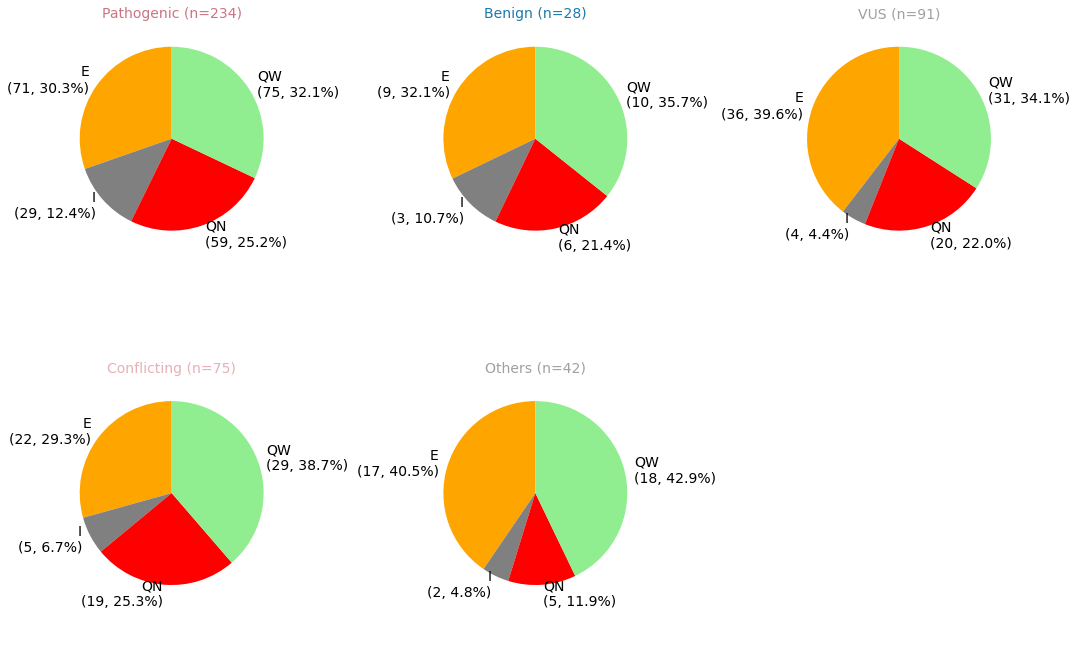

In [ ]:
# --- Per-ClinVar-category pie charts (second plot) ---
# One pie per category, ordered Pathogenic → Benign → VUS → Conflicting → Others,
# show total n in the title, and color the title using palette_dict["clinvar_clnsig_clean"]

import matplotlib.pyplot as plt

def _clinsig_bucket(name: str) -> str:
    if name is None:
        return "Others"
    n = name.split("_", 1)[-1] if "_" in name else name
    low = n.lower()
    if "pathogenic" in low:
        return "Pathogenic"
    if "benign" in low:
        return "Benign"
    if "uncertain" in low or "vus" in low:
        return "VUS"
    if "conflict" in low:
        return "Conflicting"
    return "Others"

_CLINSIG_ORDER = {"Pathogenic": 0, "Benign": 1, "VUS": 2, "Conflicting": 3, "Others": 4}
def _order_key(name: str) -> int:
    return _CLINSIG_ORDER.get(_clinsig_bucket(name), 4)

# Collect and order categories present in the data
clinvar_categories = [cat for cat in orf_distances['clinvar_clnsig_clean'].unique().to_list() if cat is not None]
clinvar_categories = sorted(clinvar_categories, key=_order_key)

if len(clinvar_categories) == 0:
    fig, ax = plt.subplots(1, 1, figsize=(6, 5))
    ax.text(0.5, 0.5, 'No ClinVar categories found', ha='center', va='center')
    ax.axis('off')
    plt.tight_layout()
    plt.show()
else:
    n_cats = len(clinvar_categories)
    n_cols = 3
    n_rows = (n_cats + n_cols - 1) // n_cols

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 5 * n_rows))
    axes = axes.flatten() if n_cats > 1 else [axes]

    per_cat_totals = {}
    for cat in clinvar_categories:
        per_cat_totals[cat] = orf_distances.filter(pl.col("clinvar_clnsig_clean") == cat).shape[0]

    # Colors for variant_class slices
    colors = {'QW': 'lightgreen', 'E': 'orange', 'QN': 'red', 'I': 'gray'}

    for i, category in enumerate(clinvar_categories):
        ax = axes[i]
        subset_data = orf_distances.filter(pl.col("clinvar_clnsig_clean") == category)
        bucket_name = _clinsig_bucket(category)
        n_cat = per_cat_totals.get(category, 0)

        if subset_data.shape[0] > 0:
            cat_summary = subset_data.group_by("variant_class").len().sort("variant_class")
            cat_summary_pd = cat_summary.to_pandas()

            if not cat_summary_pd.empty:
                cat_colors = [colors.get(x, 'gray') for x in cat_summary_pd['variant_class']]
                cat_total = cat_summary_pd['len'].sum()
                cat_percentages = (cat_summary_pd['len'] / cat_total * 100).round(1)

                cat_labels = [
                    f'{cls}\n({count}, {pct}%)'
                    for cls, count, pct in zip(
                        cat_summary_pd['variant_class'],
                        cat_summary_pd['len'],
                        cat_percentages
                    )
                ]

                ax.pie(cat_summary_pd['len'], labels=cat_labels, colors=cat_colors,
                       autopct='', startangle=90, textprops={'fontsize': 14})
                ax.set_title(f'{bucket_name} (n={n_cat})',
                             color=palette_dict["clinvar_clnsig_clean"].get(category, "black"), fontsize=14)
            else:
                ax.text(0.5, 0.5, 'No data', ha='center', va='center')
                ax.set_title(f'{bucket_name} (n=0)',
                             color=palette_dict["clinvar_clnsig_clean"].get(category, "black"))
        else:
            ax.text(0.5, 0.5, 'No data', ha='center', va='center')
            ax.set_title(f'{bucket_name} (n=0)',
                         color=palette_dict["clinvar_clnsig_clean"].get(category, "black"))

    for j in range(len(clinvar_categories), len(axes)):
        axes[j].axis('off')

    plt.tight_layout()
    plt.show()


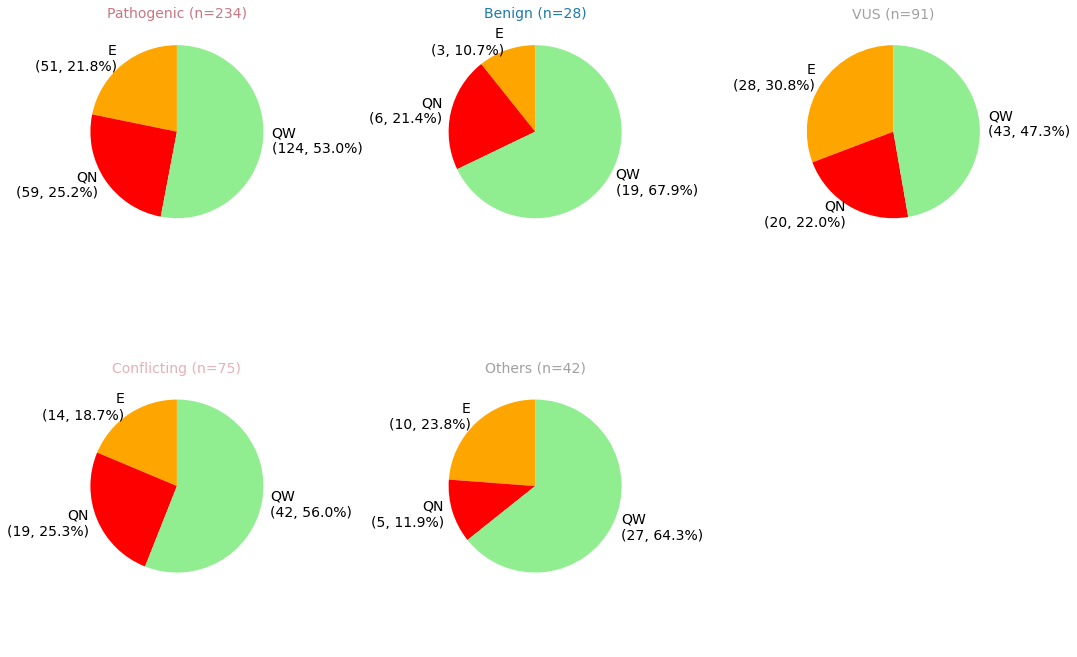

In [ ]:
# --- Per-ClinVar-category pie charts (second plot) ---
# One pie per category, ordered Pathogenic → Benign → VUS → Conflicting → Others,
# show total n in the title, and color the title using palette_dict["clinvar_clnsig_clean"]

import matplotlib.pyplot as plt

def _clinsig_bucket(name: str) -> str:
    if name is None:
        return "Others"
    n = name.split("_", 1)[-1] if "_" in name else name
    low = n.lower()
    if "pathogenic" in low:
        return "Pathogenic"
    if "benign" in low:
        return "Benign"
    if "uncertain" in low or "vus" in low:
        return "VUS"
    if "conflict" in low:
        return "Conflicting"
    return "Others"

_CLINSIG_ORDER = {"Pathogenic": 0, "Benign": 1, "VUS": 2, "Conflicting": 3, "Others": 4}
def _order_key(name: str) -> int:
    return _CLINSIG_ORDER.get(_clinsig_bucket(name), 4)

# Collect and order categories present in the data
clinvar_categories = [cat for cat in orf_distances['clinvar_clnsig_clean'].unique().to_list() if cat is not None]
clinvar_categories = sorted(clinvar_categories, key=_order_key)

if len(clinvar_categories) == 0:
    fig, ax = plt.subplots(1, 1, figsize=(6, 5))
    ax.text(0.5, 0.5, 'No ClinVar categories found', ha='center', va='center')
    ax.axis('off')
    plt.tight_layout()
    plt.show()
else:
    n_cats = len(clinvar_categories)
    n_cols = 3
    n_rows = (n_cats + n_cols - 1) // n_cols

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 5 * n_rows))
    axes = axes.flatten() if n_cats > 1 else [axes]

    per_cat_totals = {}
    for cat in clinvar_categories:
        per_cat_totals[cat] = orf_distances.filter(pl.col("clinvar_clnsig_clean") == cat).shape[0]

    # Colors for variant_class_log2fc slices
    colors = {'QW': 'lightgreen', 'E': 'orange', 'QN': 'red', 'I': 'gray'}

    for i, category in enumerate(clinvar_categories):
        ax = axes[i]
        subset_data = orf_distances.filter(pl.col("clinvar_clnsig_clean") == category)
        bucket_name = _clinsig_bucket(category)
        n_cat = per_cat_totals.get(category, 0)

        if subset_data.shape[0] > 0:
            cat_summary = subset_data.group_by("variant_class_log2fc").len().sort("variant_class_log2fc")
            cat_summary_pd = cat_summary.to_pandas()

            if not cat_summary_pd.empty:
                cat_colors = [colors.get(x, 'gray') for x in cat_summary_pd['variant_class_log2fc']]
                cat_total = cat_summary_pd['len'].sum()
                cat_percentages = (cat_summary_pd['len'] / cat_total * 100).round(1)

                cat_labels = [
                    f'{cls}\n({count}, {pct}%)'
                    for cls, count, pct in zip(
                        cat_summary_pd['variant_class_log2fc'],
                        cat_summary_pd['len'],
                        cat_percentages
                    )
                ]

                ax.pie(cat_summary_pd['len'], labels=cat_labels, colors=cat_colors,
                       autopct='', startangle=90, textprops={'fontsize': 14})
                ax.set_title(f'{bucket_name} (n={n_cat})',
                             color=palette_dict["clinvar_clnsig_clean"].get(category, "black"), fontsize=14)
            else:
                ax.text(0.5, 0.5, 'No data', ha='center', va='center')
                ax.set_title(f'{bucket_name} (n=0)',
                             color=palette_dict["clinvar_clnsig_clean"].get(category, "black"))
        else:
            ax.text(0.5, 0.5, 'No data', ha='center', va='center')
            ax.set_title(f'{bucket_name} (n=0)',
                         color=palette_dict["clinvar_clnsig_clean"].get(category, "black"))

    for j in range(len(clinvar_categories), len(axes)):
        axes[j].axis('off')

    plt.tight_layout()
    plt.show()

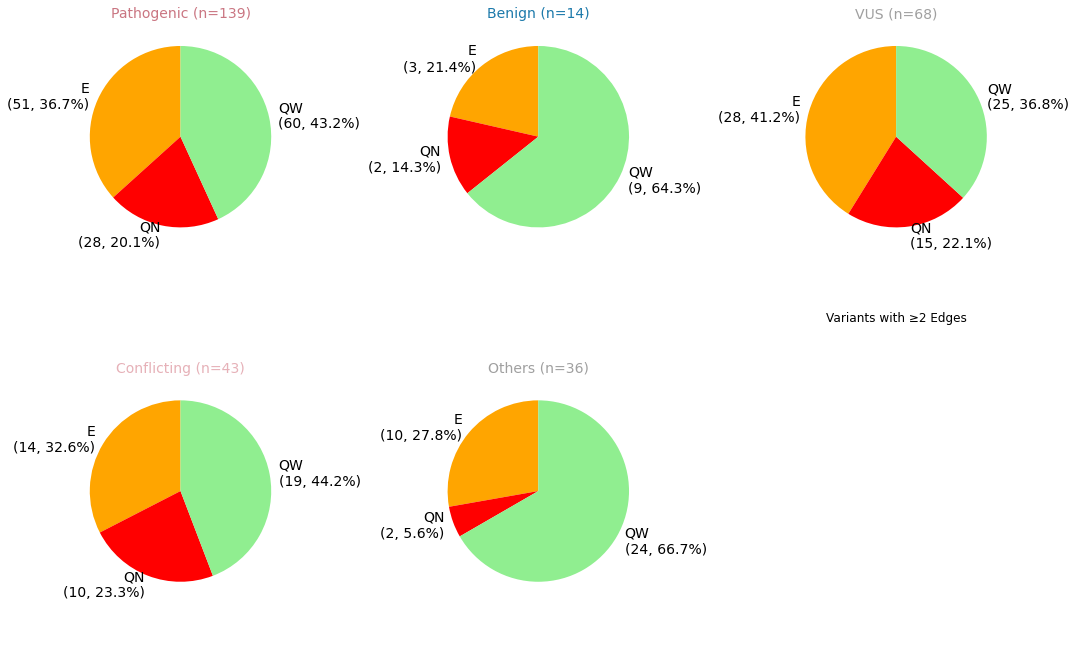

In [ ]:
# --- Per-ClinVar-category pie charts (second plot) ---
# One pie per category, ordered Pathogenic → Benign → VUS → Conflicting → Others,
# show total n in the title, and color the title using palette_dict["clinvar_clnsig_clean"]

import matplotlib.pyplot as plt

def _clinsig_bucket(name: str) -> str:
    if name is None:
        return "Others"
    n = name.split("_", 1)[-1] if "_" in name else name
    low = n.lower()
    if "pathogenic" in low:
        return "Pathogenic"
    if "benign" in low:
        return "Benign"
    if "uncertain" in low or "vus" in low:
        return "VUS"
    if "conflict" in low:
        return "Conflicting"
    return "Others"

_CLINSIG_ORDER = {"Pathogenic": 0, "Benign": 1, "VUS": 2, "Conflicting": 3, "Others": 4}
def _order_key(name: str) -> int:
    return _CLINSIG_ORDER.get(_clinsig_bucket(name), 4)

# Collect and order categories present in the data
clinvar_categories = [cat for cat in orf_distances['clinvar_clnsig_clean'].unique().to_list() if cat is not None]
clinvar_categories = sorted(clinvar_categories, key=_order_key)

orf_2_edges = orf_distances.filter(pl.col("num_edges") >= 2)

if len(clinvar_categories) == 0:
    fig, ax = plt.subplots(1, 1, figsize=(6, 5))
    ax.text(0.5, 0.5, 'No ClinVar categories found', ha='center', va='center')
    ax.axis('off')
    plt.tight_layout()
    plt.show()
else:
    n_cats = len(clinvar_categories)
    n_cols = 3
    n_rows = (n_cats + n_cols - 1) // n_cols

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 5 * n_rows))
    axes = axes.flatten() if n_cats > 1 else [axes]

    per_cat_totals = {}
    for cat in clinvar_categories:
        per_cat_totals[cat] = orf_2_edges.filter(pl.col("clinvar_clnsig_clean") == cat).shape[0]

    # Colors for variant_class_log2fc slices
    colors = {'QW': 'lightgreen', 'E': 'orange', 'QN': 'red', 'I': 'gray'}

    for i, category in enumerate(clinvar_categories):
        ax = axes[i]
        subset_data = orf_2_edges.filter(pl.col("clinvar_clnsig_clean") == category)
        bucket_name = _clinsig_bucket(category)
        n_cat = per_cat_totals.get(category, 0)

        if subset_data.shape[0] > 0:
            cat_summary = subset_data.group_by("variant_class_log2fc").len().sort("variant_class_log2fc")
            cat_summary_pd = cat_summary.to_pandas()

            if not cat_summary_pd.empty:
                cat_colors = [colors.get(x, 'gray') for x in cat_summary_pd['variant_class_log2fc']]
                cat_total = cat_summary_pd['len'].sum()
                cat_percentages = (cat_summary_pd['len'] / cat_total * 100).round(1)

                cat_labels = [
                    f'{cls}\n({count}, {pct}%)'
                    for cls, count, pct in zip(
                        cat_summary_pd['variant_class_log2fc'],
                        cat_summary_pd['len'],
                        cat_percentages
                    )
                ]

                ax.pie(cat_summary_pd['len'], labels=cat_labels, colors=cat_colors,
                       autopct='', startangle=90, textprops={'fontsize': 14})
                ax.set_title(f'{bucket_name} (n={n_cat})',
                             color=palette_dict["clinvar_clnsig_clean"].get(category, "black"), fontsize=14)
            else:
                ax.text(0.5, 0.5, 'No data', ha='center', va='center')
                ax.set_title(f'{bucket_name} (n=0)',
                             color=palette_dict["clinvar_clnsig_clean"].get(category, "black"))
        else:
            ax.text(0.5, 0.5, 'No data', ha='center', va='center')
            ax.set_title(f'{bucket_name} (n=0)',
                         color=palette_dict["clinvar_clnsig_clean"].get(category, "black"))

    for j in range(len(clinvar_categories), len(axes)):
        axes[j].axis('off')

    plt.tight_layout()
    plt.title('Variants with ≥2 Edges')
    plt.show()

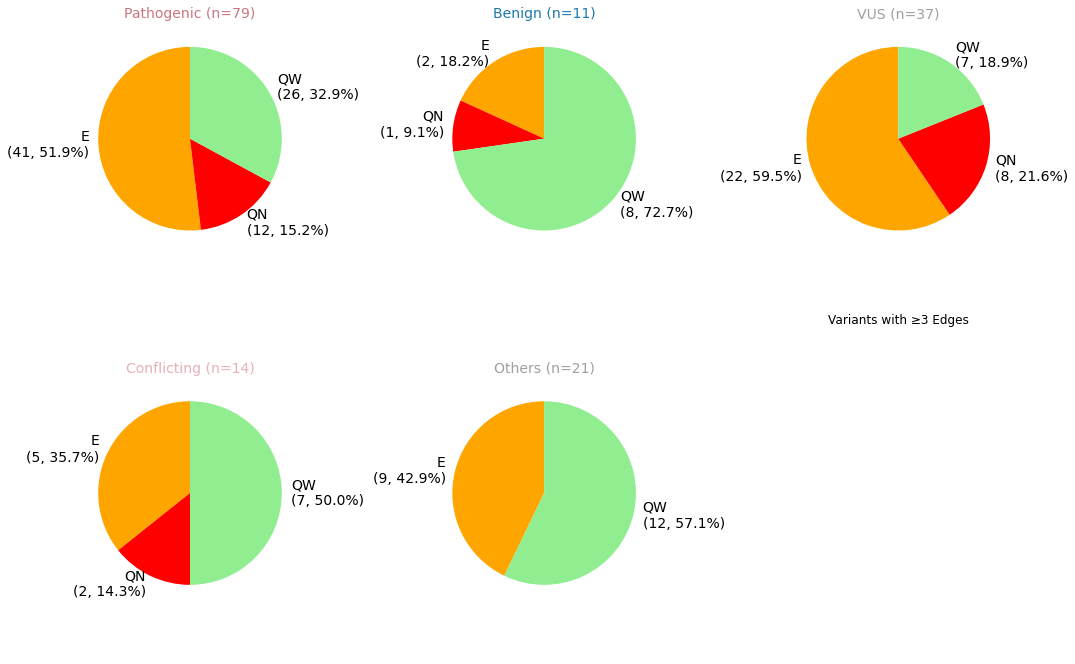

In [ ]:
# --- Per-ClinVar-category pie charts (second plot) ---
# One pie per category, ordered Pathogenic → Benign → VUS → Conflicting → Others,
# show total n in the title, and color the title using palette_dict["clinvar_clnsig_clean"]

import matplotlib.pyplot as plt

def _clinsig_bucket(name: str) -> str:
    if name is None:
        return "Others"
    n = name.split("_", 1)[-1] if "_" in name else name
    low = n.lower()
    if "pathogenic" in low:
        return "Pathogenic"
    if "benign" in low:
        return "Benign"
    if "uncertain" in low or "vus" in low:
        return "VUS"
    if "conflict" in low:
        return "Conflicting"
    return "Others"

_CLINSIG_ORDER = {"Pathogenic": 0, "Benign": 1, "VUS": 2, "Conflicting": 3, "Others": 4}
def _order_key(name: str) -> int:
    return _CLINSIG_ORDER.get(_clinsig_bucket(name), 4)

# Collect and order categories present in the data
clinvar_categories = [cat for cat in orf_distances['clinvar_clnsig_clean'].unique().to_list() if cat is not None]
clinvar_categories = sorted(clinvar_categories, key=_order_key)

orf_2_edges = orf_distances.filter(pl.col("num_edges") >= 3)

if len(clinvar_categories) == 0:
    fig, ax = plt.subplots(1, 1, figsize=(6, 5))
    ax.text(0.5, 0.5, 'No ClinVar categories found', ha='center', va='center')
    ax.axis('off')
    plt.tight_layout()
    plt.show()
else:
    n_cats = len(clinvar_categories)
    n_cols = 3
    n_rows = (n_cats + n_cols - 1) // n_cols

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 5 * n_rows))
    axes = axes.flatten() if n_cats > 1 else [axes]

    per_cat_totals = {}
    for cat in clinvar_categories:
        per_cat_totals[cat] = orf_2_edges.filter(pl.col("clinvar_clnsig_clean") == cat).shape[0]

    # Colors for variant_class_log2fc slices
    colors = {'QW': 'lightgreen', 'E': 'orange', 'QN': 'red', 'I': 'gray'}

    for i, category in enumerate(clinvar_categories):
        ax = axes[i]
        subset_data = orf_2_edges.filter(pl.col("clinvar_clnsig_clean") == category)
        bucket_name = _clinsig_bucket(category)
        n_cat = per_cat_totals.get(category, 0)

        if subset_data.shape[0] > 0:
            cat_summary = subset_data.group_by("variant_class_log2fc").len().sort("variant_class_log2fc")
            cat_summary_pd = cat_summary.to_pandas()

            if not cat_summary_pd.empty:
                cat_colors = [colors.get(x, 'gray') for x in cat_summary_pd['variant_class_log2fc']]
                cat_total = cat_summary_pd['len'].sum()
                cat_percentages = (cat_summary_pd['len'] / cat_total * 100).round(1)

                cat_labels = [
                    f'{cls}\n({count}, {pct}%)'
                    for cls, count, pct in zip(
                        cat_summary_pd['variant_class_log2fc'],
                        cat_summary_pd['len'],
                        cat_percentages
                    )
                ]

                ax.pie(cat_summary_pd['len'], labels=cat_labels, colors=cat_colors,
                       autopct='', startangle=90, textprops={'fontsize': 14})
                ax.set_title(f'{bucket_name} (n={n_cat})',
                             color=palette_dict["clinvar_clnsig_clean"].get(category, "black"), fontsize=14)
            else:
                ax.text(0.5, 0.5, 'No data', ha='center', va='center')
                ax.set_title(f'{bucket_name} (n=0)',
                             color=palette_dict["clinvar_clnsig_clean"].get(category, "black"))
        else:
            ax.text(0.5, 0.5, 'No data', ha='center', va='center')
            ax.set_title(f'{bucket_name} (n=0)',
                         color=palette_dict["clinvar_clnsig_clean"].get(category, "black"))

    for j in range(len(clinvar_categories), len(axes)):
        axes[j].axis('off')

    plt.tight_layout()
    plt.title('Variants with ≥3 Edges')
    plt.show()


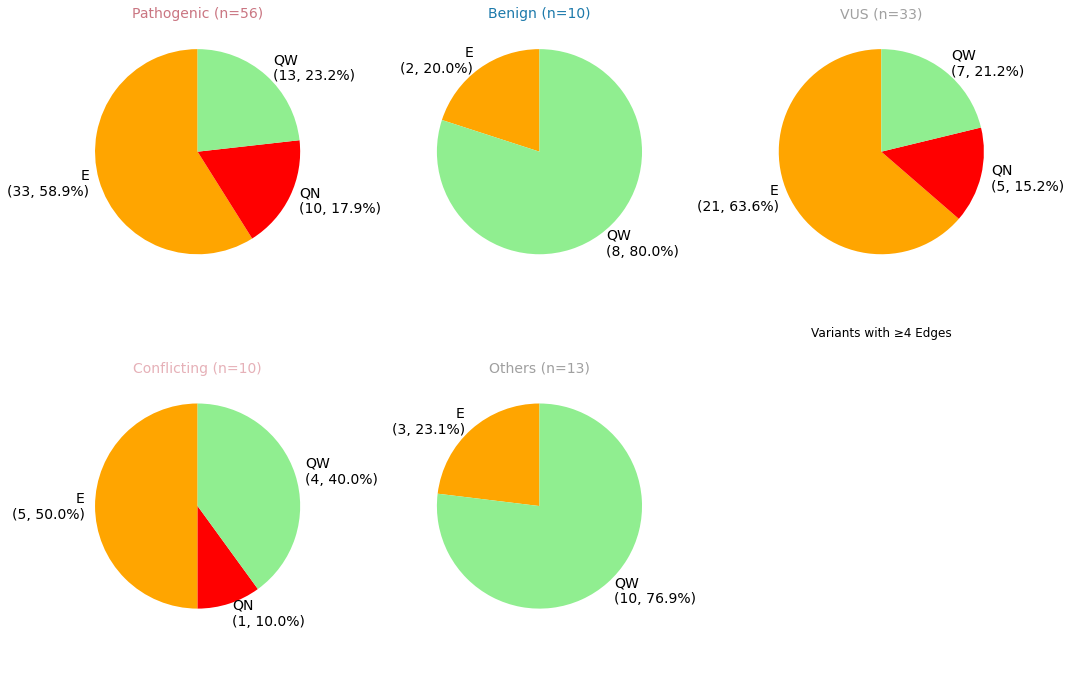

In [ ]:
# --- Per-ClinVar-category pie charts (second plot) ---
# One pie per category, ordered Pathogenic → Benign → VUS → Conflicting → Others,
# show total n in the title, and color the title using palette_dict["clinvar_clnsig_clean"]

import matplotlib.pyplot as plt

def _clinsig_bucket(name: str) -> str:
    if name is None:
        return "Others"
    n = name.split("_", 1)[-1] if "_" in name else name
    low = n.lower()
    if "pathogenic" in low:
        return "Pathogenic"
    if "benign" in low:
        return "Benign"
    if "uncertain" in low or "vus" in low:
        return "VUS"
    if "conflict" in low:
        return "Conflicting"
    return "Others"

_CLINSIG_ORDER = {"Pathogenic": 0, "Benign": 1, "VUS": 2, "Conflicting": 3, "Others": 4}
def _order_key(name: str) -> int:
    return _CLINSIG_ORDER.get(_clinsig_bucket(name), 4)

# Collect and order categories present in the data
clinvar_categories = [cat for cat in orf_distances['clinvar_clnsig_clean'].unique().to_list() if cat is not None]
clinvar_categories = sorted(clinvar_categories, key=_order_key)

orf_2_edges = orf_distances.filter(pl.col("num_edges") >= 4)

if len(clinvar_categories) == 0:
    fig, ax = plt.subplots(1, 1, figsize=(6, 5))
    ax.text(0.5, 0.5, 'No ClinVar categories found', ha='center', va='center')
    ax.axis('off')
    plt.tight_layout()
    plt.show()
else:
    n_cats = len(clinvar_categories)
    n_cols = 3
    n_rows = (n_cats + n_cols - 1) // n_cols

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 5 * n_rows))
    axes = axes.flatten() if n_cats > 1 else [axes]

    per_cat_totals = {}
    for cat in clinvar_categories:
        per_cat_totals[cat] = orf_2_edges.filter(pl.col("clinvar_clnsig_clean") == cat).shape[0]

    # Colors for variant_class_log2fc slices
    colors = {'QW': 'lightgreen', 'E': 'orange', 'QN': 'red', 'I': 'gray'}

    for i, category in enumerate(clinvar_categories):
        ax = axes[i]
        subset_data = orf_2_edges.filter(pl.col("clinvar_clnsig_clean") == category)
        bucket_name = _clinsig_bucket(category)
        n_cat = per_cat_totals.get(category, 0)

        if subset_data.shape[0] > 0:
            cat_summary = subset_data.group_by("variant_class_log2fc").len().sort("variant_class_log2fc")
            cat_summary_pd = cat_summary.to_pandas()

            if not cat_summary_pd.empty:
                cat_colors = [colors.get(x, 'gray') for x in cat_summary_pd['variant_class_log2fc']]
                cat_total = cat_summary_pd['len'].sum()
                cat_percentages = (cat_summary_pd['len'] / cat_total * 100).round(1)

                cat_labels = [
                    f'{cls}\n({count}, {pct}%)'
                    for cls, count, pct in zip(
                        cat_summary_pd['variant_class_log2fc'],
                        cat_summary_pd['len'],
                        cat_percentages
                    )
                ]

                ax.pie(cat_summary_pd['len'], labels=cat_labels, colors=cat_colors,
                       autopct='', startangle=90, textprops={'fontsize': 14})
                ax.set_title(f'{bucket_name} (n={n_cat})',
                             color=palette_dict["clinvar_clnsig_clean"].get(category, "black"), fontsize=14)
            else:
                ax.text(0.5, 0.5, 'No data', ha='center', va='center')
                ax.set_title(f'{bucket_name} (n=0)',
                             color=palette_dict["clinvar_clnsig_clean"].get(category, "black"))
        else:
            ax.text(0.5, 0.5, 'No data', ha='center', va='center')
            ax.set_title(f'{bucket_name} (n=0)',
                         color=palette_dict["clinvar_clnsig_clean"].get(category, "black"))

    for j in range(len(clinvar_categories), len(axes)):
        axes[j].axis('off')

    plt.tight_layout()
    plt.title('Variants with ≥4 Edges')
    plt.show()


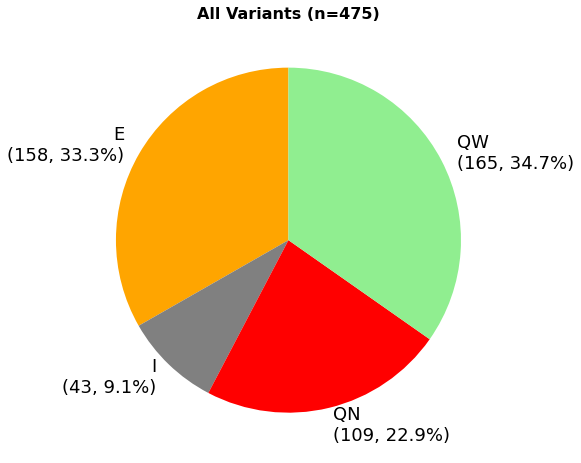

Summary of all variants:
  E: 158 (33.3%)
  I: 43 (9.1%)
  QN: 109 (22.9%)
  QW: 165 (34.7%)


In [ ]:
# Create pie chart for all variants regardless of ClinVar classification
fig, ax = plt.subplots(1, 1, figsize=(8, 8))

# Colors for variant classes
variant_colors = {'E': 'orange', 'QN': 'red', 'QW': 'lightgreen', 'I': 'gray'}

# Get variant class counts for all variants
all_variant_summary = orf_distances.group_by("variant_class").len().sort("variant_class")
all_variant_summary_pd = all_variant_summary.to_pandas()

if not all_variant_summary_pd.empty:
    total = all_variant_summary_pd['len'].sum()
    
    # Calculate percentages
    percentages = (all_variant_summary_pd['len'] / total * 100).round(1)
    
    # Create labels with counts and percentages
    labels = [f'{cls}\n({count}, {pct}%)' 
             for cls, count, pct in zip(all_variant_summary_pd['variant_class'], 
                                      all_variant_summary_pd['len'], 
                                      percentages)]
    
    # Get colors for each variant class
    colors = [variant_colors.get(cls, 'gray') for cls in all_variant_summary_pd['variant_class']]
    
    # Create pie chart
    ax.pie(all_variant_summary_pd['len'], 
           labels=labels, 
           colors=colors,
           autopct='',
           startangle=90,
           textprops={'fontsize': 18})
    
    ax.set_title(f'All Variants (n={total})', fontsize=16, fontweight='bold')
else:
    ax.text(0.5, 0.5, 'No data', ha='center', va='center')
    ax.set_title('All Variants (n=0)', fontsize=16, fontweight='bold')

plt.tight_layout()
plt.show()

# Print summary statistics
print("Summary of all variants:")
total_variants = orf_distances.shape[0]
for row in all_variant_summary.iter_rows():
    variant_class, count = row
    percentage = (count / total_variants) * 100
    print(f"  {variant_class}: {count} ({percentage:.1f}%)")

In [ ]:
orf_distances

db_orf_id,db_mut_id,euclid_distance,max_perturbation,max_relative_perturbation,max_perturbation_abs,max_perturbation_fold,max_perturbation_fold_abs,max_log2_fold_change,max_log2_fold_change_abs,mahalanobis_distance,mahalanobis_distance_reg,num_edges,all_edges_severely_perturbed,fraction_severely_perturbed,mean_perturbation,mean_relative_perturbation,std_relative_perturbation,min_edge_value,min_relative_edge_value,no_edges_perturbed,inconclusive,mean_wt,log2fc_perturbed,log2fc_no_perturbed,fraction_log2fc_perturbed,normalized_euclid_distance,normalized_euclid_distance_normalized,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,variant_class,variant_class_log2fc
str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,i64,bool,f64,f64,f64,f64,f64,f64,bool,bool,f64,bool,bool,f64,f64,f64,str,str,str,str,str,str,f64,f64,str,str,str
"""54308""","""3142""",0.035523,0.035523,-0.088319,0.035523,1.096875,1.096875,0.133399,0.133399,null,0.287211,1,false,0.0,-0.035523,-0.088319,null,0.366692,0.911681,true,false,0.402215,false,true,0.0,0.035523,0.044786,"""PKP2""","""Asp26Asn""","""76G>A""","""ENSG00000057294""","""Edgotyping3""","""2_Benign""",null,2.0,"""PKP2_Asp26Asn""","""QW""","""QW"""
"""3689""","""214851""",0.336779,0.336779,-0.664435,0.336779,2.980051,2.980051,1.575337,1.575337,null,2.216505,1,true,1.0,-0.336779,-0.664435,null,0.170086,0.335565,false,false,0.506865,true,false,1.0,0.336779,0.424594,"""GCK""","""Gly299Arg""","""895G>C""","""ENSG00000106633""","""CEGS2""","""1_Pathogenic""",null,2.0,"""GCK_Gly299Arg""","""QN""","""QN"""
"""8999""","""202990""",0.112924,0.112924,-0.496102,0.112924,1.984527,1.984527,0.988795,0.988795,null,0.828907,1,false,0.0,-0.112924,-0.496102,null,0.114699,0.503898,false,true,0.227623,false,true,0.0,0.112924,0.142369,"""TTR""","""Val50Gly""","""149T>G""","""ENSG00000118271""","""CEGS2""","""1_Pathogenic""",null,1.0,"""TTR_Val50Gly""","""I""","""QW"""
"""11805""","""2140""",0.426794,0.36572,-0.732844,0.36572,4.968626,4.968626,2.312847,2.312847,null,2.003187,2,true,1.0,-0.292863,-0.76579,0.046594,0.080203,0.201263,false,false,0.37904,true,false,1.0,0.301789,0.38048,"""SMAD3""","""Glu239Lys""","""715G>A""","""ENSG00000166949""","""Edgotyping3""","""1_Pathogenic""",null,2.0,"""SMAD3_Glu239Lys""","""QN""","""QN"""
"""281""","""744""",0.071094,0.071094,-0.364746,0.071094,1.574175,1.574175,0.654596,0.654596,null,0.957641,1,false,0.0,-0.071094,-0.364746,null,0.123819,0.635254,false,true,0.194913,false,true,0.0,0.071094,0.089632,"""MVK""","""Asn205Asp""","""613A>G""","""ENSG00000110921""","""RC4""","""1_Pathogenic""",0.000027,2.0,"""MVK_Asn205Asp""","""I""","""QW"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""12739""","""203835""",0.06374,-0.06374,1.08795,0.06374,0.478939,0.478939,-1.062087,1.062087,null,2.325991,1,false,0.0,0.06374,1.08795,null,0.122327,2.08795,true,false,0.058587,false,true,0.0,0.06374,0.08036,"""GNAI3""","""Ser47Arg""","""141C>A""","""ENSG00000065135""","""CEGS2""","""1_Pathogenic""",null,null,"""GNAI3_Ser47Arg""","""QW""","""QW"""
"""70497""","""3872""",0.397021,0.397021,-0.859629,0.397021,7.123992,7.123992,2.832686,2.832686,null,1.802413,1,true,1.0,-0.397021,-0.859629,null,0.064831,0.140371,false,false,0.461852,true,false,1.0,0.397021,0.500544,"""AGXT""","""Arg289Cys""","""865C>T""","""ENSG00000172482""","""Edgotyping3""","""4_VUS""",0.000456,2.0,"""AGXT_Arg289Cys""","""QN""","""QN"""
"""6983""","""216125""",0.255858,0.251423,-0.239168,0.251423,4.184375,4.184375,2.065012,2.065012,null,2.07653,2,false,0.5,-0.149428,-0.500092,0.369002,0.078955,0.238984,false,false,0.264352,false,false,0.5,0.180919,0.228094,"""PITX2""","""Arg144Pro""","""431G>C""","""ENSG00000164093""","""CEGS2""","""1_Pathogenic""",null,2.0,"""PITX2_Arg144Pro""","""E""","""E"""


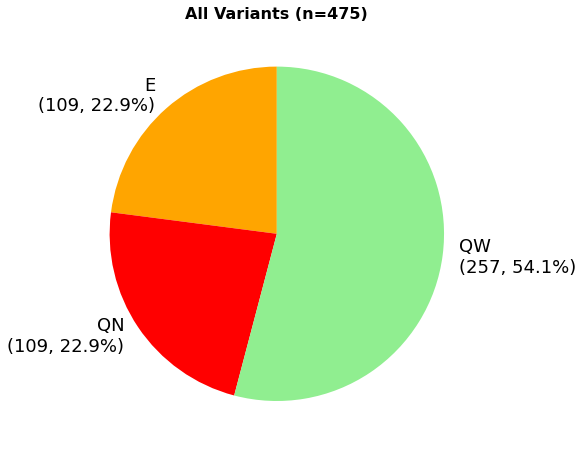

Summary of all variants:
  E: 109 (22.9%)
  QN: 109 (22.9%)
  QW: 257 (54.1%)


In [ ]:
# Create pie chart for all variants regardless of ClinVar classification
fig, ax = plt.subplots(1, 1, figsize=(8, 8))

# Colors for variant classes
variant_colors = {'E': 'orange', 'QN': 'red', 'QW': 'lightgreen', 'I': 'gray'}

# Get variant class counts for all variants
all_variant_summary = orf_distances.group_by("variant_class_log2fc").len().sort("variant_class_log2fc")
all_variant_summary_pd = all_variant_summary.to_pandas()

if not all_variant_summary_pd.empty:
    total = all_variant_summary_pd['len'].sum()
    
    # Calculate percentages
    percentages = (all_variant_summary_pd['len'] / total * 100).round(1)
    
    # Create labels with counts and percentages
    labels = [f'{cls}\n({count}, {pct}%)' 
             for cls, count, pct in zip(all_variant_summary_pd['variant_class_log2fc'], 
                                      all_variant_summary_pd['len'], 
                                      percentages)]
    
    # Get colors for each variant class
    colors = [variant_colors.get(cls, 'gray') for cls in all_variant_summary_pd['variant_class_log2fc']]
    
    # Create pie chart
    ax.pie(all_variant_summary_pd['len'], 
           labels=labels, 
           colors=colors,
           autopct='',
           startangle=90,
           textprops={'fontsize': 18})
    
    ax.set_title(f'All Variants (n={total})', fontsize=16, fontweight='bold')
else:
    ax.text(0.5, 0.5, 'No data', ha='center', va='center')
    ax.set_title('All Variants (n=0)', fontsize=16, fontweight='bold')

plt.tight_layout()
plt.show()

# Print summary statistics
print("Summary of all variants:")
total_variants = orf_distances.shape[0]
for row in all_variant_summary.iter_rows():
    variant_class_log2fc, count = row
    percentage = (count / total_variants) * 100
    print(f"  {variant_class_log2fc}: {count} ({percentage:.1f}%)")

# LWH1

In [ ]:
from scipy.spatial.distance import mahalanobis
from scipy.linalg import pinv

# Calculate Euclidean distance for each variant relative to it's wildtype reference
orf_profiles = [f for f in os.listdir(f"{outputs_dir}/edgotype_profiles/auto_lwh1") if "_auto_lwh1" in f]

zero_col = "0"
perturbed_thresh = 0.5 # edge called "perturbed" if >= 50% decrease compared to wt reference
orf_distances_lwh1 = []

all_perturbations = []
all_log2s = []

wt_thresh = [0, 0.1, 0.2, 0.3, 0.4, 0.5]

for orf in orf_profiles:
    profiles = pl.read_csv(f"{outputs_dir}/edgotype_profiles/auto_lwh1/{orf}")
    
    # filter out edges where the WT could not be measured
    profiles = profiles.filter(~pl.col("0").is_null())

    db_orf_id = orf.replace("orf_id_", "")
    db_orf_id = db_orf_id.replace("_auto_lwh1.csv", "")

    columns = [col for col in profiles.columns if col != "ad_orf_id"]

    # "impute" missing values as the mean for that variant
    profiles_filled = profiles.with_columns([
        pl.when(pl.col(col).is_null())
        .then(pl.col(col).mean())
        .otherwise(pl.col(col))
        .alias(col)
        for col in columns
    ])
    # print('db_orf_id', db_orf_id)
    
    # compute distances
    distance_rows = []
    for col in columns:
        if col == zero_col:
            continue
        
        # Euclidean distance
        diff_squared = (profiles_filled[col] - profiles_filled[zero_col]) ** 2
        distances = np.sqrt(diff_squared.sum())

        # Cosine similarity
        wt = profiles_filled.select(zero_col).to_numpy()
        var = profiles_filled.select(col).to_numpy()

        # Add to your distance calculation loop
        max_perturbation = (profiles_filled[zero_col] - profiles_filled[col]).max()
        max_perturbation_abs = abs(max_perturbation)
        max_perturbation_fold = (profiles_filled[zero_col] / profiles_filled[col]).max()
        # max_perturbation_fold = (profiles_filled[col] / profiles_filled[zero_col]).max()
        max_perturbation_fold_abs = abs(max_perturbation_fold)
        max_relative_perturbation = ((profiles_filled[col] - profiles_filled[zero_col]) / profiles_filled[zero_col]).max()
        # Log2 fold change calculation
        max_log2_fold_change = np.log2(max_perturbation_fold) if max_perturbation_fold > 0 else np.log2(max_perturbation_fold + 0.0001)
        max_log2_fold_change_abs = abs(max_log2_fold_change) if max_log2_fold_change is not None else None

        
        # Node removal detection metrics
        # perturbations = profiles_filled[zero_col] - profiles_filled[col] 
        perturbations = profiles_filled[col] -  profiles_filled[zero_col] 
        relative_perturbations = perturbations / profiles_filled[zero_col]
        all_perturbations.append(relative_perturbations.to_list())
        # print('var', profiles_filled[col])
        # print('wt', profiles_filled[zero_col])
        # print('perturb',relative_perturbations)
        
        log2fc = np.log2((profiles_filled[col] / profiles_filled[zero_col]) + 0.0001)
        all_log2s.append(log2fc.to_list())
        
        mean_wt = profiles_filled[zero_col].mean()
        
        if (relative_perturbations >5).any():
            print('WARNING: relative perturbations > 5, check data')

        # Check if all edges are severely perturbed
        severe_perturbation_threshold = 0.75  # 50% decrease
        low_threshold = 0.50 # 10% decrease
        all_edges_perturbed = (relative_perturbations <= -severe_perturbation_threshold).all()
        # print('all_edges_perturbed', all_edges_perturbed)
        fraction_severely_perturbed = (relative_perturbations <= -severe_perturbation_threshold).mean()
        # print('_________________________________')
        
        no_edges_perturbed = (relative_perturbations > -low_threshold).all()
        
        inconclusive = (
            (relative_perturbations <= -low_threshold) & 
            (relative_perturbations > -severe_perturbation_threshold)
        ).all()
        
        log2fc_tresh = -1
        
        log2fc_all_perturbed = (log2fc <= log2fc_tresh).all()
        log2fc_no_perturbed = (log2fc > log2fc_tresh).all()  # corresponds to <20% decrease
        # log2fc fraction of edges perturbed
        fraction_log2fc_perturbed = (log2fc <= log2fc_tresh).mean()

        # Mean perturbation across all edges
        mean_perturbation = perturbations.mean()
        mean_relative_perturbation = relative_perturbations.mean()

        # Standard deviation of perturbations (low = uniform perturbation)
        std_relative_perturbation = relative_perturbations.std()

        # Minimum edge value (close to 0 = complete loss)
        min_edge_value = profiles_filled[col].min()
        min_relative_edge_value = (profiles_filled[col] / profiles_filled[zero_col]).min()


        # if wt.ndim == 1:
        #     wt = wt.reshape(-1, 1)
        # if var.ndim == 1:
        #     var = var.reshape(-1, 1)
        # cos_sim = cosine_similarity(wt.T, var.T)
        # cos_dist = 1 - cos_sim

        # calculate frac perturbed
        wt_pass = []
        per_edges = []
        # for thresh in wt_thresh:
        #     filt_wt = profiles.filter(pl.col("0") > thresh)
        #     wt_pass.append(filt_wt.shape[0])
        #     per_edges.append(filt_wt.filter((pl.col(col)/pl.col("0")) <= perturbed_thresh).shape[0])   
            
            # Mahalanobis distance
        try:
            # Calculate covariance matrix from all profiles
            profile_matrix = profiles_filled.select([col for col in columns]).to_numpy().T
            cov_matrix = np.cov(profile_matrix)
            
            # Use pseudo-inverse for numerical stability
            inv_cov_matrix = pinv(cov_matrix)
            
            wt_profile = profiles_filled.select(zero_col).to_numpy().flatten()
            var_profile = profiles_filled.select(col).to_numpy().flatten()
            
            mahal_distance = mahalanobis(var_profile, wt_profile, inv_cov_matrix)
        except:
            # Fallback if covariance matrix is singular
            mahal_distance = None
            

        distance_rows.append({
            "db_orf_id": db_orf_id,
            "db_mut_id": int(col),
            "euclid_distance": distances,
            "max_perturbation": max_perturbation,
            "max_relative_perturbation": max_relative_perturbation,
            "max_perturbation_abs": max_perturbation_abs,
            "max_perturbation_fold": max_perturbation_fold,
            "max_perturbation_fold_abs": max_perturbation_fold_abs,
            "max_log2_fold_change": max_log2_fold_change,
            "max_log2_fold_change_abs": max_log2_fold_change_abs,
            "mahalanobis_distance": mahal_distance,
            # "cosine_distance": cos_dist,
            "num_edges": profiles.shape[0],
            "all_edges_severely_perturbed": all_edges_perturbed,
            "fraction_severely_perturbed": fraction_severely_perturbed,
            "mean_perturbation": mean_perturbation,
            "mean_relative_perturbation": mean_relative_perturbation,
            "std_relative_perturbation": std_relative_perturbation,
            "min_edge_value": min_edge_value,
            "min_relative_edge_value": min_relative_edge_value,
            'no_edges_perturbed': no_edges_perturbed,
            'inconclusive': inconclusive,
            "mean_wt": mean_wt,
            "log2fc_perturbed": log2fc_all_perturbed,
            "log2fc_no_perturbed": log2fc_no_perturbed,
            "fraction_log2fc_perturbed": fraction_log2fc_perturbed,
            # "num_zero_wt": profiles.filter(pl.col("0") == 0).shape[0],
            # "num_per_0.0": per_edges[0],
            # "num_per_0.1": per_edges[1],
            # "num_per_0.2": per_edges[2],
            # "num_per_0.3": per_edges[3],
            # "num_per_0.4": per_edges[4],
            # "num_per_0.5": per_edges[5],
            # "num_edge_0.0": wt_pass[0],
            # "num_edge_0.1": wt_pass[1],
            # "num_edge_0.2": wt_pass[2],
            # "num_edge_0.3": wt_pass[3],
            # "num_edge_0.4": wt_pass[4],
            # "num_edge_0.5": wt_pass[5],
            # "frac_per_0.0": per_edges[0]/wt_pass[0] if wt_pass[0] != 0 else None,
            # "frac_per_0.1": per_edges[1]/wt_pass[1] if wt_pass[1] != 0 else None,
            # "frac_per_0.2": per_edges[2]/wt_pass[2] if wt_pass[2] != 0 else None,
            # "frac_per_0.3": per_edges[3]/wt_pass[3] if wt_pass[3] != 0 else None,
            # "frac_per_0.4": per_edges[4]/wt_pass[4] if wt_pass[4] != 0 else None,
            # "frac_per_0.5": per_edges[5]/wt_pass[5] if wt_pass[5] != 0 else None
        })


    result_profiles = pl.DataFrame(distance_rows)
    orf_distances_lwh1.append(result_profiles)

# concatentate and normalize wrt dimensionality
orf_distances_lwh1 = pl.concat(orf_distances_lwh1, how="vertical_relaxed")
orf_distances_lwh1 = orf_distances_lwh1.with_columns(
    (pl.col("euclid_distance") / pl.col("num_edges").cast(pl.Float64).sqrt()).alias("normalized_euclid_distance"),
    pl.col("db_mut_id").cast(pl.String).alias("db_mut_id"),
    pl.col("db_orf_id").cast(pl.String).alias("db_orf_id"),
)


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_61483/280647448.py:133: RuntimeWarning: Degrees of freedom <= 0 for slice
  cov_matrix = np.cov(profile_matrix)
/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/numpy/lib/function_base.py:2748: RuntimeWarning: divide by zero encountered in divide
  c *= np.true_divide(1, fact)
/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/numpy/lib/function_base.py:2748: RuntimeWarning: invalid value encountered in multiply
  c *= np.true_divide(1, fact)


In [ ]:
orf_distances_lwh1

db_orf_id,db_mut_id,euclid_distance,max_perturbation,max_relative_perturbation,max_perturbation_abs,max_perturbation_fold,max_perturbation_fold_abs,max_log2_fold_change,max_log2_fold_change_abs,mahalanobis_distance,num_edges,all_edges_severely_perturbed,fraction_severely_perturbed,mean_perturbation,mean_relative_perturbation,std_relative_perturbation,min_edge_value,min_relative_edge_value,no_edges_perturbed,inconclusive,mean_wt,log2fc_perturbed,log2fc_no_perturbed,fraction_log2fc_perturbed,normalized_euclid_distance
str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,i64,bool,f64,f64,f64,f64,f64,f64,bool,bool,f64,bool,bool,f64,f64
"""8420""","""216668""",16.424182,-16.424182,0.033675,16.424182,0.967422,0.967422,-0.047783,0.047783,null,1,false,0.0,16.424182,0.033675,null,504.144783,1.033675,true,false,487.720602,false,true,0.0,16.424182
"""8420""","""216661""",93.312749,93.312749,-0.191324,93.312749,1.236589,1.236589,0.306367,0.306367,null,1,false,0.0,-93.312749,-0.191324,null,394.407853,0.808676,true,false,487.720602,false,true,0.0,93.312749
"""8420""","""216656""",52.924079,52.924079,-0.108513,52.924079,1.121721,1.121721,0.165715,0.165715,null,1,false,0.0,-52.924079,-0.108513,null,434.796523,0.891487,true,false,487.720602,false,true,0.0,52.924079
"""8420""","""216660""",443.868967,443.868967,-0.910089,443.868967,11.122062,11.122062,3.475352,3.475352,null,1,true,1.0,-443.868967,-0.910089,null,43.851635,0.089911,false,false,487.720602,true,false,1.0,443.868967
"""8420""","""216657""",64.043251,-64.043251,0.131311,64.043251,0.88393,0.88393,-0.177996,0.177996,null,1,false,0.0,64.043251,0.131311,null,551.763853,1.131311,true,false,487.720602,false,true,0.0,64.043251
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""6983""","""216119""",3.422885,-3.422885,0.00763,3.422885,0.992428,0.992428,-0.010965,0.010965,null,1,false,0.0,3.422885,0.00763,null,452.055898,1.00763,true,false,448.633013,false,true,0.0,3.422885
"""6983""","""216121""",409.79445,409.79445,-0.913429,409.79445,11.551226,11.551226,3.529974,3.529974,null,1,true,1.0,-409.79445,-0.913429,null,38.838563,0.086571,false,false,448.633013,true,false,1.0,409.79445
"""6983""","""216123""",290.250004,290.250004,-0.646965,290.250004,2.832583,2.832583,1.502118,1.502118,null,1,false,0.0,-290.250004,-0.646965,null,158.383008,0.353035,false,true,448.633013,true,false,1.0,290.250004


In [ ]:
# Map LWH1 columns onto main orf_distances dataframe
lwh1_columns = orf_distances_lwh1.select([
    "db_orf_id", 
    "db_mut_id", 
    "normalized_euclid_distance", 
    "log2fc_perturbed", 
    "log2fc_no_perturbed",
    "fraction_log2fc_perturbed",
]).rename({
    "normalized_euclid_distance": "lwh1_normalized_euclid_distance",
    "log2fc_perturbed": "lwh1_log2fc_perturbed", 
    "log2fc_no_perturbed": "lwh1_log2fc_no_perturbed",
    "fraction_log2fc_perturbed": "lwh1_fraction_log2fc_perturbed"
})

# Join with main dataframe
orf_distances = orf_distances.join(
    lwh1_columns,
    on=["db_orf_id", "db_mut_id"],
    how="left"
)

orf_distances

db_orf_id,db_mut_id,euclid_distance,max_perturbation,max_relative_perturbation,max_perturbation_abs,max_perturbation_fold,max_perturbation_fold_abs,max_log2_fold_change,max_log2_fold_change_abs,mahalanobis_distance,mahalanobis_distance_reg,num_edges,all_edges_severely_perturbed,fraction_severely_perturbed,mean_perturbation,mean_relative_perturbation,std_relative_perturbation,min_edge_value,min_relative_edge_value,no_edges_perturbed,inconclusive,mean_wt,log2fc_perturbed,log2fc_no_perturbed,fraction_log2fc_perturbed,normalized_euclid_distance,normalized_euclid_distance_normalized,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,variant_class,variant_class_log2fc,lwh1_normalized_euclid_distance,lwh1_log2fc_perturbed,lwh1_log2fc_no_perturbed,lwh1_fraction_log2fc_perturbed
str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,i64,bool,f64,f64,f64,f64,f64,f64,bool,bool,f64,bool,bool,f64,f64,f64,str,str,str,str,str,str,f64,f64,str,str,str,f64,bool,bool,f64
"""54308""","""3142""",0.035523,0.035523,-0.088319,0.035523,1.096875,1.096875,0.133399,0.133399,null,0.287211,1,false,0.0,-0.035523,-0.088319,null,0.366692,0.911681,true,false,0.402215,false,true,0.0,0.035523,0.044786,"""PKP2""","""Asp26Asn""","""76G>A""","""ENSG00000057294""","""Edgotyping3""","""2_Benign""",null,2.0,"""PKP2_Asp26Asn""","""QW""","""QW""",62.392168,false,true,0.0
"""3689""","""214851""",0.336779,0.336779,-0.664435,0.336779,2.980051,2.980051,1.575337,1.575337,null,2.216505,1,true,1.0,-0.336779,-0.664435,null,0.170086,0.335565,false,false,0.506865,true,false,1.0,0.336779,0.424594,"""GCK""","""Gly299Arg""","""895G>C""","""ENSG00000106633""","""CEGS2""","""1_Pathogenic""",null,2.0,"""GCK_Gly299Arg""","""QN""","""QN""",null,null,null,null
"""8999""","""202990""",0.112924,0.112924,-0.496102,0.112924,1.984527,1.984527,0.988795,0.988795,null,0.828907,1,false,0.0,-0.112924,-0.496102,null,0.114699,0.503898,false,true,0.227623,false,true,0.0,0.112924,0.142369,"""TTR""","""Val50Gly""","""149T>G""","""ENSG00000118271""","""CEGS2""","""1_Pathogenic""",null,1.0,"""TTR_Val50Gly""","""I""","""QW""",null,null,null,null
"""11805""","""2140""",0.426794,0.36572,-0.732844,0.36572,4.968626,4.968626,2.312847,2.312847,null,2.003187,2,true,1.0,-0.292863,-0.76579,0.046594,0.080203,0.201263,false,false,0.37904,true,false,1.0,0.301789,0.38048,"""SMAD3""","""Glu239Lys""","""715G>A""","""ENSG00000166949""","""Edgotyping3""","""1_Pathogenic""",null,2.0,"""SMAD3_Glu239Lys""","""QN""","""QN""",null,null,null,null
"""281""","""744""",0.071094,0.071094,-0.364746,0.071094,1.574175,1.574175,0.654596,0.654596,null,0.957641,1,false,0.0,-0.071094,-0.364746,null,0.123819,0.635254,false,true,0.194913,false,true,0.0,0.071094,0.089632,"""MVK""","""Asn205Asp""","""613A>G""","""ENSG00000110921""","""RC4""","""1_Pathogenic""",0.000027,2.0,"""MVK_Asn205Asp""","""I""","""QW""",228.300988,false,true,0.0
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""12739""","""203835""",0.06374,-0.06374,1.08795,0.06374,0.478939,0.478939,-1.062087,1.062087,null,2.325991,1,false,0.0,0.06374,1.08795,null,0.122327,2.08795,true,false,0.058587,false,true,0.0,0.06374,0.08036,"""GNAI3""","""Ser47Arg""","""141C>A""","""ENSG00000065135""","""CEGS2""","""1_Pathogenic""",null,null,"""GNAI3_Ser47Arg""","""QW""","""QW""",null,null,null,null
"""70497""","""3872""",0.397021,0.397021,-0.859629,0.397021,7.123992,7.123992,2.832686,2.832686,null,1.802413,1,true,1.0,-0.397021,-0.859629,null,0.064831,0.140371,false,false,0.461852,true,false,1.0,0.397021,0.500544,"""AGXT""","""Arg289Cys""","""865C>T""","""ENSG00000172482""","""Edgotyping3""","""4_VUS""",0.000456,2.0,"""AGXT_Arg289Cys""","""QN""","""QN""",417.372891,true,false,1.0
"""6983""","""216125""",0.255858,0.251423,-0.239168,0.251423,4.184375,4.184375,2.065012,2.065012,null,2.07653,2,false,0.5,-0.149428,-0.500092,0.369002,0.078955,0.238984,false,false,0.264352,false,false,0.5,0.180919,0.228094,"""PITX2""","

In [ ]:
# Characterize variants based on perturbation patterns
orf_distances = orf_distances.with_columns(
    pl.when(pl.col("lwh1_log2fc_perturbed") == True)
    .then(pl.lit("QN"))  # Quasi-null: all edges severely perturbed
    .when(pl.col("lwh1_log2fc_no_perturbed") == True)
    .then(pl.lit("QW"))  # Wild-type like: no edges perturbed
    .when(pl.col("lwh1_log2fc_perturbed").is_null() | pl.col("lwh1_log2fc_no_perturbed").is_null())
    .then(pl.lit(None))   # null
    .otherwise(pl.lit("E"))  # Edgetic: some but not all edges perturbed
    .alias("variant_class_log2fc_lwh1")
)

orf_distances.write_csv(f"{outputs_dir}/6_variants_perturbation_scores_automated_annotated.csv")

In [ ]:
orf_distances

db_orf_id,db_mut_id,euclid_distance,max_perturbation,max_relative_perturbation,max_perturbation_abs,max_perturbation_fold,max_perturbation_fold_abs,max_log2_fold_change,max_log2_fold_change_abs,mahalanobis_distance,mahalanobis_distance_reg,num_edges,all_edges_severely_perturbed,fraction_severely_perturbed,mean_perturbation,mean_relative_perturbation,std_relative_perturbation,min_edge_value,min_relative_edge_value,no_edges_perturbed,inconclusive,mean_wt,log2fc_perturbed,log2fc_no_perturbed,fraction_log2fc_perturbed,normalized_euclid_distance,normalized_euclid_distance_normalized,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,variant_class,variant_class_log2fc,lwh1_normalized_euclid_distance,lwh1_log2fc_perturbed,lwh1_log2fc_no_perturbed,lwh1_fraction_log2fc_perturbed,variant_class_log2fc_lwh1
str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,i64,bool,f64,f64,f64,f64,f64,f64,bool,bool,f64,bool,bool,f64,f64,f64,str,str,str,str,str,str,f64,f64,str,str,str,f64,bool,bool,f64,str
"""54308""","""3142""",0.035523,0.035523,-0.088319,0.035523,1.096875,1.096875,0.133399,0.133399,null,0.287211,1,false,0.0,-0.035523,-0.088319,null,0.366692,0.911681,true,false,0.402215,false,true,0.0,0.035523,0.044786,"""PKP2""","""Asp26Asn""","""76G>A""","""ENSG00000057294""","""Edgotyping3""","""2_Benign""",null,2.0,"""PKP2_Asp26Asn""","""QW""","""QW""",62.392168,false,true,0.0,"""QW"""
"""3689""","""214851""",0.336779,0.336779,-0.664435,0.336779,2.980051,2.980051,1.575337,1.575337,null,2.216505,1,true,1.0,-0.336779,-0.664435,null,0.170086,0.335565,false,false,0.506865,true,false,1.0,0.336779,0.424594,"""GCK""","""Gly299Arg""","""895G>C""","""ENSG00000106633""","""CEGS2""","""1_Pathogenic""",null,2.0,"""GCK_Gly299Arg""","""QN""","""QN""",null,null,null,null,null
"""8999""","""202990""",0.112924,0.112924,-0.496102,0.112924,1.984527,1.984527,0.988795,0.988795,null,0.828907,1,false,0.0,-0.112924,-0.496102,null,0.114699,0.503898,false,true,0.227623,false,true,0.0,0.112924,0.142369,"""TTR""","""Val50Gly""","""149T>G""","""ENSG00000118271""","""CEGS2""","""1_Pathogenic""",null,1.0,"""TTR_Val50Gly""","""I""","""QW""",null,null,null,null,null
"""11805""","""2140""",0.426794,0.36572,-0.732844,0.36572,4.968626,4.968626,2.312847,2.312847,null,2.003187,2,true,1.0,-0.292863,-0.76579,0.046594,0.080203,0.201263,false,false,0.37904,true,false,1.0,0.301789,0.38048,"""SMAD3""","""Glu239Lys""","""715G>A""","""ENSG00000166949""","""Edgotyping3""","""1_Pathogenic""",null,2.0,"""SMAD3_Glu239Lys""","""QN""","""QN""",null,null,null,null,null
"""281""","""744""",0.071094,0.071094,-0.364746,0.071094,1.574175,1.574175,0.654596,0.654596,null,0.957641,1,false,0.0,-0.071094,-0.364746,null,0.123819,0.635254,false,true,0.194913,false,true,0.0,0.071094,0.089632,"""MVK""","""Asn205Asp""","""613A>G""","""ENSG00000110921""","""RC4""","""1_Pathogenic""",0.000027,2.0,"""MVK_Asn205Asp""","""I""","""QW""",228.300988,false,true,0.0,"""QW"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""12739""","""203835""",0.06374,-0.06374,1.08795,0.06374,0.478939,0.478939,-1.062087,1.062087,null,2.325991,1,false,0.0,0.06374,1.08795,null,0.122327,2.08795,true,false,0.058587,false,true,0.0,0.06374,0.08036,"""GNAI3""","""Ser47Arg""","""141C>A""","""ENSG00000065135""","""CEGS2""","""1_Pathogenic""",null,null,"""GNAI3_Ser47Arg""","""QW""","""QW""",null,null,null,null,null
"""70497""","""3872""",0.397021,0.397021,-0.859629,0.397021,7.123992,7.123992,2.832686,2.832686,null,1.802413,1,true,1.0,-0.397021,-0.859629,null,0.064831,0.140371,false,false,0.461852,true,false,1.0,0.397021,0.500544,"""AGXT""","""Arg289Cys""","""865C>T""","""ENSG00000172482""","""Edgotyping3""","""4_VUS""",0.000456,2.0,"""AGXT_Arg289Cys""","""QN""","""QN""",417.372891,true,false,1.0,"""QN"""
"""6983""","""216125""",0.255858,0.251423,-0.239168,0.251423,4.184375,4.184375,2.065012,2.065012,null,2.07653,2,false,0.5,-0.149428,-0.500092,0.369002,0.07895

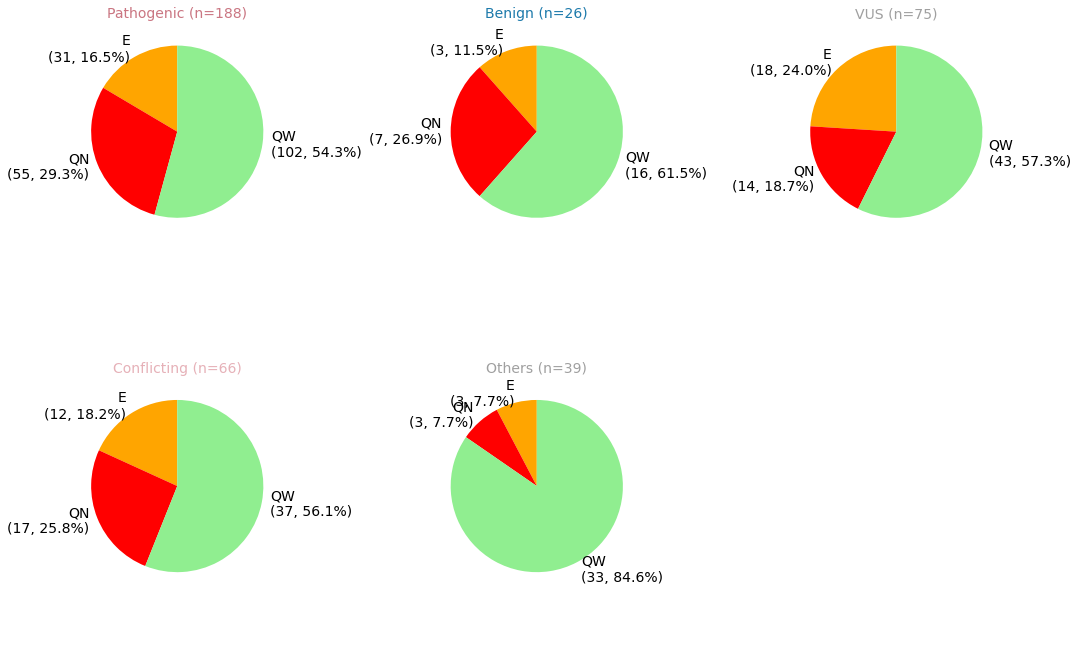

In [ ]:
# --- Per-ClinVar-category pie charts (second plot) ---
# One pie per category, ordered Pathogenic → Benign → VUS → Conflicting → Others,
# show total n in the title, and color the title using palette_dict["clinvar_clnsig_clean"]

import matplotlib.pyplot as plt

def _clinsig_bucket(name: str) -> str:
    if name is None:
        return "Others"
    n = name.split("_", 1)[-1] if "_" in name else name
    low = n.lower()
    if "pathogenic" in low:
        return "Pathogenic"
    if "benign" in low:
        return "Benign"
    if "uncertain" in low or "vus" in low:
        return "VUS"
    if "conflict" in low:
        return "Conflicting"
    return "Others"

_CLINSIG_ORDER = {"Pathogenic": 0, "Benign": 1, "VUS": 2, "Conflicting": 3, "Others": 4}
def _order_key(name: str) -> int:
    return _CLINSIG_ORDER.get(_clinsig_bucket(name), 4)

plot_df = orf_distances.filter(pl.col("lwh1_normalized_euclid_distance").is_not_null())
# plot_df = plot_df.filter(pl.col("num_edges") >= 2)


# Collect and order categories present in the data
clinvar_categories = [cat for cat in plot_df['clinvar_clnsig_clean'].unique().to_list() if cat is not None]
clinvar_categories = sorted(clinvar_categories, key=_order_key)


if len(clinvar_categories) == 0:
    fig, ax = plt.subplots(1, 1, figsize=(6, 5))
    ax.text(0.5, 0.5, 'No ClinVar categories found', ha='center', va='center')
    ax.axis('off')
    plt.tight_layout()
    plt.show()
else:
    n_cats = len(clinvar_categories)
    n_cols = 3
    n_rows = (n_cats + n_cols - 1) // n_cols

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 5 * n_rows))
    axes = axes.flatten() if n_cats > 1 else [axes]

    per_cat_totals = {}
    for cat in clinvar_categories:
        per_cat_totals[cat] = plot_df.filter(pl.col("clinvar_clnsig_clean") == cat).shape[0]

    # Colors for variant_class_log2fc_lwh1 slices
    colors = {'QW': 'lightgreen', 'E': 'orange', 'QN': 'red', 'I': 'gray'}

    for i, category in enumerate(clinvar_categories):
        ax = axes[i]
        subset_data = plot_df.filter(pl.col("clinvar_clnsig_clean") == category)
        bucket_name = _clinsig_bucket(category)
        n_cat = per_cat_totals.get(category, 0)

        if subset_data.shape[0] > 0:
            cat_summary = subset_data.group_by("variant_class_log2fc_lwh1").len().sort("variant_class_log2fc_lwh1")
            cat_summary_pd = cat_summary.to_pandas()

            if not cat_summary_pd.empty:
                cat_colors = [colors.get(x, 'gray') for x in cat_summary_pd['variant_class_log2fc_lwh1']]
                cat_total = cat_summary_pd['len'].sum()
                cat_percentages = (cat_summary_pd['len'] / cat_total * 100).round(1)

                cat_labels = [
                    f'{cls}\n({count}, {pct}%)'
                    for cls, count, pct in zip(
                        cat_summary_pd['variant_class_log2fc_lwh1'],
                        cat_summary_pd['len'],
                        cat_percentages
                    )
                ]

                ax.pie(cat_summary_pd['len'], labels=cat_labels, colors=cat_colors,
                       autopct='', startangle=90, textprops={'fontsize': 14})
                ax.set_title(f'{bucket_name} (n={n_cat})',
                             color=palette_dict["clinvar_clnsig_clean"].get(category, "black"), fontsize=14)
            else:
                ax.text(0.5, 0.5, 'No data', ha='center', va='center')
                ax.set_title(f'{bucket_name} (n=0)',
                             color=palette_dict["clinvar_clnsig_clean"].get(category, "black"))
        else:
            ax.text(0.5, 0.5, 'No data', ha='center', va='center')
            ax.set_title(f'{bucket_name} (n=0)',
                         color=palette_dict["clinvar_clnsig_clean"].get(category, "black"))

    for j in range(len(clinvar_categories), len(axes)):
        axes[j].axis('off')

    plt.tight_layout()
    plt.show()

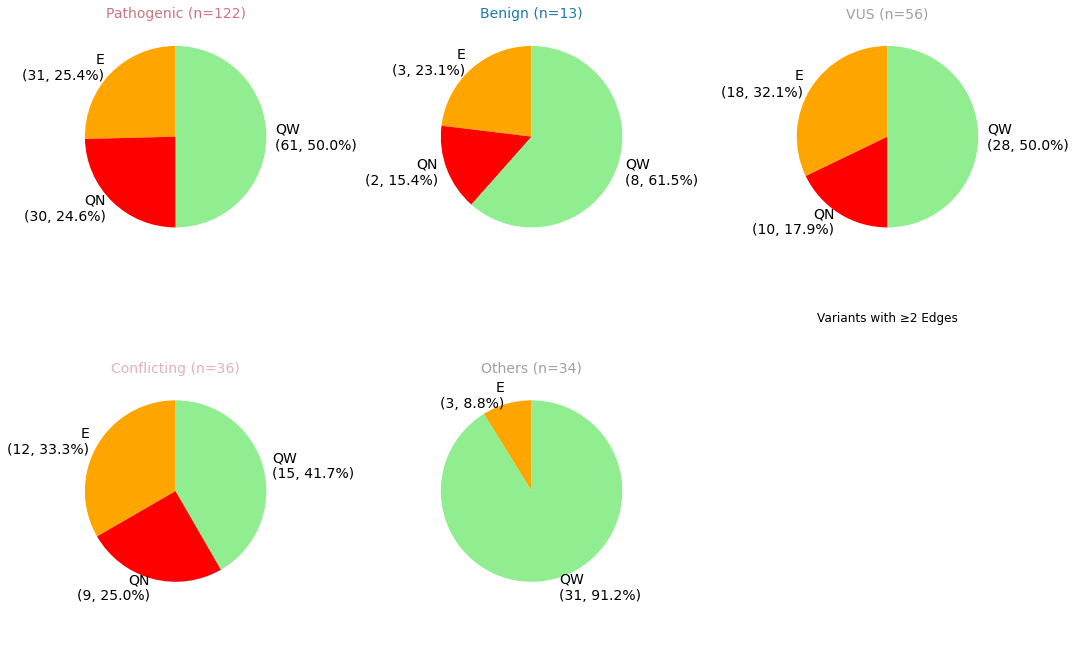

In [ ]:
# --- Per-ClinVar-category pie charts (second plot) ---
# One pie per category, ordered Pathogenic → Benign → VUS → Conflicting → Others,
# show total n in the title, and color the title using palette_dict["clinvar_clnsig_clean"]

import matplotlib.pyplot as plt

def _clinsig_bucket(name: str) -> str:
    if name is None:
        return "Others"
    n = name.split("_", 1)[-1] if "_" in name else name
    low = n.lower()
    if "pathogenic" in low:
        return "Pathogenic"
    if "benign" in low:
        return "Benign"
    if "uncertain" in low or "vus" in low:
        return "VUS"
    if "conflict" in low:
        return "Conflicting"
    return "Others"

_CLINSIG_ORDER = {"Pathogenic": 0, "Benign": 1, "VUS": 2, "Conflicting": 3, "Others": 4}
def _order_key(name: str) -> int:
    return _CLINSIG_ORDER.get(_clinsig_bucket(name), 4)

plot_df = orf_distances.filter(pl.col("lwh1_normalized_euclid_distance").is_not_null())
plot_df = plot_df.filter(pl.col("num_edges") >= 2)


# Collect and order categories present in the data
clinvar_categories = [cat for cat in plot_df['clinvar_clnsig_clean'].unique().to_list() if cat is not None]
clinvar_categories = sorted(clinvar_categories, key=_order_key)


if len(clinvar_categories) == 0:
    fig, ax = plt.subplots(1, 1, figsize=(6, 5))
    ax.text(0.5, 0.5, 'No ClinVar categories found', ha='center', va='center')
    ax.axis('off')
    plt.tight_layout()
    plt.show()
else:
    n_cats = len(clinvar_categories)
    n_cols = 3
    n_rows = (n_cats + n_cols - 1) // n_cols

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 5 * n_rows))
    axes = axes.flatten() if n_cats > 1 else [axes]

    per_cat_totals = {}
    for cat in clinvar_categories:
        per_cat_totals[cat] = plot_df.filter(pl.col("clinvar_clnsig_clean") == cat).shape[0]

    # Colors for variant_class_log2fc_lwh1 slices
    colors = {'QW': 'lightgreen', 'E': 'orange', 'QN': 'red', 'I': 'gray'}

    for i, category in enumerate(clinvar_categories):
        ax = axes[i]
        subset_data = plot_df.filter(pl.col("clinvar_clnsig_clean") == category)
        bucket_name = _clinsig_bucket(category)
        n_cat = per_cat_totals.get(category, 0)

        if subset_data.shape[0] > 0:
            cat_summary = subset_data.group_by("variant_class_log2fc_lwh1").len().sort("variant_class_log2fc_lwh1")
            cat_summary_pd = cat_summary.to_pandas()

            if not cat_summary_pd.empty:
                cat_colors = [colors.get(x, 'gray') for x in cat_summary_pd['variant_class_log2fc_lwh1']]
                cat_total = cat_summary_pd['len'].sum()
                cat_percentages = (cat_summary_pd['len'] / cat_total * 100).round(1)

                cat_labels = [
                    f'{cls}\n({count}, {pct}%)'
                    for cls, count, pct in zip(
                        cat_summary_pd['variant_class_log2fc_lwh1'],
                        cat_summary_pd['len'],
                        cat_percentages
                    )
                ]

                ax.pie(cat_summary_pd['len'], labels=cat_labels, colors=cat_colors,
                       autopct='', startangle=90, textprops={'fontsize': 14})
                ax.set_title(f'{bucket_name} (n={n_cat})',
                             color=palette_dict["clinvar_clnsig_clean"].get(category, "black"), fontsize=14)
            else:
                ax.text(0.5, 0.5, 'No data', ha='center', va='center')
                ax.set_title(f'{bucket_name} (n=0)',
                             color=palette_dict["clinvar_clnsig_clean"].get(category, "black"))
        else:
            ax.text(0.5, 0.5, 'No data', ha='center', va='center')
            ax.set_title(f'{bucket_name} (n=0)',
                         color=palette_dict["clinvar_clnsig_clean"].get(category, "black"))

    for j in range(len(clinvar_categories), len(axes)):
        axes[j].axis('off')

    plt.title('Variants with ≥2 Edges')
    plt.tight_layout()
    plt.show()